This code downloads wind data from ERA5.

In [1]:
import os
from pathlib import Path
ROOT         = str(Path.cwd().resolve().parent)  # repository root; run notebooks from analysis/

WIND_NC_PATH = f'{ROOT}/data/climate/wind/era5_wind_indonesia_2015_2025.nc'

if not os.path.exists(WIND_NC_PATH):
    import cdsapi

    # Reads the API key from the CDSAPI_KEY environment variable rather than
    # hardcoding it in the notebook. Set it before launching Jupyter, e.g.:
    #   export CDSAPI_KEY="your-key-here"
    api_key = os.environ.get('CDSAPI_KEY')
    if not api_key:
        raise RuntimeError(
            'ERA5 wind file not found locally and CDSAPI_KEY is not set. '
            'Either place the file at WIND_NC_PATH, or set the CDSAPI_KEY '
            'environment variable to download it.'
        )

    c = cdsapi.Client(url='https://cds.climate.copernicus.eu/api', key=api_key)
    c.retrieve(
        'reanalysis-era5-single-levels-monthly-means',
        {
            'product_type': 'monthly_averaged_reanalysis',
            'variable': [
                '10m_u_component_of_wind',
                '10m_v_component_of_wind',
            ],
            'year': [str(y) for y in range(2015, 2026)],
            'month': [f'{m:02d}' for m in range(1, 13)],
            'time': '00:00',
            'area': [6, 95, -11, 141],
            'format': 'netcdf',
            'grid': '0.25/0.25',
        },
        WIND_NC_PATH,
    )
    print(f'Downloaded ERA5 wind data to {WIND_NC_PATH}')
else:
    print(f'ERA5 wind file already exists at {WIND_NC_PATH} -- skipping download.')

ERA5 wind file already exists at /Users/hariaksha/Documents/GitHub/climate-conflict/data/climate/wind/era5_wind_indonesia_2015_2025.nc -- skipping download.


## 1. Imports and configuration

All paths are relative to wherever you run the notebook. Set `DATA_DIR` to the folder containing your fire CSV and ACLED xlsx.

In [2]:
import warnings
import re
import difflib
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pyfixest as pf
from pathlib import Path
ROOT         = str(Path.cwd().resolve().parent)  # repository root; run notebooks from analysis/
from scipy.spatial import cKDTree

warnings.filterwarnings('ignore')

# ── Paths ─────────────────────────────────────────────────────────────────
WIND_NC     = f'{ROOT}/data/climate/wind/era5_wind_indonesia_2015_2025.nc'
FIRE_CSV    = f'{ROOT}/data/climate/fire/DL_FIRE_SUOMI-VIIRS-C2_718931_Nov2000-Feb2026_buffer0km-csv/fire_archive_SV-C2_718931.csv'
ACLED_XLSX  = f'{ROOT}/data/unrest/ACLED Data_2026-06-10.xlsx'
DISTRICT_SHP = f'{ROOT}/data/administrative/gadm41_IDN_shp/gadm41_IDN_2.shp'

# ── Parameters ────────────────────────────────────────────────────────────
UPWIND_RADIUS_KM  = 300   # search radius for upwind fires
UPWIND_HALF_ANG   = 45    # ± degrees from upwind direction
START_YEAR        = 2015
END_YEAR          = 2025
END_MONTH         = 6
N_LAGS            = 1 # controls how many monthly lags of fire exposure to include as additional regressors in model
R_EARTH           = 6371.0  # km, for distance conversions

POLITICAL_VIOLENCE = [
    'Riots', 'Violence against civilians',
    'Battles', 'Explosions/Remote violence',
]

print('All imports OK')

All imports OK


## 1b. Load district (kabupaten/kota) boundaries

We use GADM41 admin2 polygons (502 districts) as the spatial backbone for assigning fire
detections and wind grid cells to districts, and for computing district centroids used in
the upwind instrument. This replaces the earlier ACLED-bounding-box approach with true
point-in-polygon spatial joins.

In [3]:
districts_gdf = gpd.read_file(DISTRICT_SHP)[['NAME_1', 'NAME_2', 'geometry']].rename(
    columns={'NAME_1': 'province', 'NAME_2': 'district'}
)

# A handful of district names are duplicated across provinces (e.g. "Banjar" exists in
# both West Java and South Kalimantan). Disambiguate so `district` is a unique key.
dup_mask = districts_gdf['district'].duplicated(keep=False)
districts_gdf.loc[dup_mask, 'district'] = (
    districts_gdf.loc[dup_mask, 'district'] + ' (' + districts_gdf.loc[dup_mask, 'province'] + ')'
)

# Representative point (guaranteed inside the polygon, even for archipelagos) used as
# the district "centroid" for the upwind-instrument bearing/distance calculations.
rep_points = districts_gdf.geometry.representative_point()
districts_gdf['dist_lat'] = rep_points.y
districts_gdf['dist_lon'] = rep_points.x

district_to_prov = dict(zip(districts_gdf['district'], districts_gdf['province']))

print(f'Districts loaded: {len(districts_gdf):,}')
print(districts_gdf[['province', 'district', 'dist_lat', 'dist_lon']].head())

Districts loaded: 502
  province         district  dist_lat   dist_lon
0     Aceh       Aceh Barat  4.451205  96.200535
1     Aceh  Aceh Barat Daya  3.835823  96.847922
2     Aceh       Aceh Besar  5.354748  95.496192
3     Aceh        Aceh Jaya  4.810597  95.698874
4     Aceh     Aceh Selatan  3.070028  97.468794


## 2. Load ERA5 wind data and compute wind direction

ERA5 provides:
- **u10**: eastward (positive = blowing east)
- **v10**: northward (positive = blowing north)

We derive the direction the wind is **blowing from** (meteorological convention, degrees clockwise from north), and wind speed. These are aggregated to province level by averaging over grid cells within each province's bounding box.

In [4]:
ds = xr.open_dataset(WIND_NC)
print('Wind dataset variables:', list(ds.data_vars))
print('Dimensions:', dict(ds.dims))
print('Time range:', ds.valid_time.values[[0, -1]] if 'valid_time' in ds
      else ds.time.values[[0, -1]])

# Normalise dimension names
if 'valid_time' in ds.coords:
    ds = ds.rename({'valid_time': 'time'})

# Pull u and v arrays
u_da = ds['u10'] if 'u10' in ds else ds[list(ds.data_vars)[0]]
v_da = ds['v10'] if 'v10' in ds else ds[list(ds.data_vars)[1]]

# Convert to dataframe
u_df = u_da.to_dataframe(name='u10').reset_index()
v_df = v_da.to_dataframe(name='v10').reset_index()
wind_df = u_df.merge(v_df, on=['time', 'latitude', 'longitude'])

# Parse year/month
wind_df['time'] = pd.to_datetime(wind_df['time'])
wind_df['year']  = wind_df['time'].dt.year
wind_df['month'] = wind_df['time'].dt.month
wind_df = wind_df[(wind_df['year'] >= START_YEAR) &
                   ~((wind_df['year'] == END_YEAR) & (wind_df['month'] > END_MONTH))]

# Wind speed and direction
wind_df['wind_speed']    = np.sqrt(wind_df['u10']**2 + wind_df['v10']**2)
wind_df['wind_dir_from'] = (np.degrees(np.arctan2(wind_df['u10'],
                                                    wind_df['v10'])) + 180) % 360

print(f'\nWind grid points per month: {wind_df.groupby(["year","month"]).size().mean():.0f}')
print(f'Wind speed  — mean: {wind_df.wind_speed.mean():.2f} m/s  '
      f'max: {wind_df.wind_speed.max():.2f} m/s')
print(wind_df[['latitude','longitude','year','month',
               'u10','v10','wind_speed','wind_dir_from']].head())

Wind dataset variables: ['u10', 'v10']
Dimensions: {'valid_time': 132, 'latitude': 69, 'longitude': 185}
Time range: ['2015-01-01T00:00:00.000000000' '2025-12-01T00:00:00.000000000']

Wind grid points per month: 12765
Wind speed  — mean: 2.85 m/s  max: 10.25 m/s
   latitude  longitude  year  month       u10       v10  wind_speed  \
0       6.0      95.00  2015      1 -5.425678 -0.700418    5.470701   
1       6.0      95.25  2015      1 -5.431049 -0.367411    5.443463   
2       6.0      95.50  2015      1 -5.124897  0.068624    5.125357   
3       6.0      95.75  2015      1 -4.750385  0.175558    4.753628   
4       6.0      96.00  2015      1 -4.547749  0.045187    4.547973   

   wind_dir_from  
0      82.644188  
1      86.129837  
2      90.767174  
3      92.116501  
4      90.569283  


## 3. Load ACLED conflict data

We aggregate events to district-month for two outcomes:
- **events**: all ACLED event types
- **pv_events**: political violence only (riots, battles, violence against civilians, explosions)

ACLED's `admin2` field uses English-translated district names (e.g. "East Jakarta"),
while the GADM district polygons use Indonesian names (e.g. "Jakarta Timur"). We build a
mapping between the two naming conventions (direct match → manual overrides for known
renames → directional-word translation rules), then aggregate conflict to the matched
GADM districts. A small number of ACLED districts (mostly post-2014 "pemekaran"
regencies not present in GADM 4.1) cannot be matched and are dropped.

In [5]:
# ── Assign ACLED events to GADM districts by coordinates ───────────────────
# ACLED's `admin2` field uses a single name for a city and the surrounding
# regency (e.g. "Bandung" covers both Kota Bandung and Kabupaten Bandung), and
# it does not track post-2012 regency splits. Matching on that name therefore
# put most city events into the neighbouring regency and dropped events in
# split or renamed districts. Instead, each event is placed in the GADM Level-2
# polygon that contains its reported coordinates. The few events whose
# coordinates fall just offshore (outside every land polygon) are assigned to
# the nearest district polygon within NEAREST_MAX_KM.
NEAREST_MAX_KM = 20

acled = pd.read_excel(
    ACLED_XLSX,
    usecols=['event_date','admin1','admin2','event_type','fatalities',
             'latitude','longitude','geo_precision']
)
acled['event_date'] = pd.to_datetime(acled['event_date'])
acled['year']       = acled['event_date'].dt.year
acled['month']      = acled['event_date'].dt.month
acled['is_pv']      = acled['event_type'].isin(POLITICAL_VIOLENCE)

acled_gdf = gpd.GeoDataFrame(
    acled,
    geometry=gpd.points_from_xy(acled['longitude'], acled['latitude']),
    crs='EPSG:4326'
)
acled_joined = gpd.sjoin(
    acled_gdf, districts_gdf[['district', 'geometry']],
    how='left', predicate='within'
)
acled_joined = acled_joined[~acled_joined.index.duplicated(keep='first')]
acled['district'] = acled_joined['district'].reindex(acled.index).values
n_within = acled['district'].notna().sum()

offshore = acled['district'].isna()
if offshore.any():
    near = gpd.sjoin_nearest(
        acled_gdf.loc[offshore].to_crs(3395),
        districts_gdf[['district', 'geometry']].to_crs(3395),
        how='left', max_distance=NEAREST_MAX_KM * 1000, distance_col='dist_m'
    )
    near = near[~near.index.duplicated(keep='first')]
    acled.loc[offshore, 'district'] = near['district'].reindex(acled.index[offshore]).values

n_before = len(acled)
acled_matched = acled.dropna(subset=['district']).copy()
n_after = len(acled_matched)

print(f'ACLED events placed inside a district polygon: {n_within:,}; '
      f'offshore events assigned to nearest district: {n_after - n_within:,}; '
      f'unassigned: {n_before - n_after:,}')
print(f'ACLED events retained: {n_after:,}/{n_before:,} ({n_after/n_before*100:.1f}%)')

conflict_pm = (
    acled_matched.groupby(['district','year','month'])
    .agg(events=('event_type','count'),
         pv_events=('is_pv','sum'),
         fatalities=('fatalities','sum'))
    .reset_index()
)

print(f'\nDistricts with conflict data: {conflict_pm["district"].nunique()}')
print(f'All events: {n_after:,}  |  '
      f'Political violence: {acled_matched["is_pv"].sum():,} '
      f'({acled_matched["is_pv"].mean()*100:.1f}%)')
print(conflict_pm.head())


ACLED events placed inside a district polygon: 21,667; offshore events assigned to nearest district: 36; unassigned: 0
ACLED events retained: 21,703/21,703 (100.0%)

Districts with conflict data: 481
All events: 21,703  |  Political violence: 3,546 (16.3%)
     district  year  month  events  pv_events  fatalities
0  Aceh Barat  2015      7       2          0           0
1  Aceh Barat  2016      5       1          0           0
2  Aceh Barat  2016      6       1          0           0
3  Aceh Barat  2017      8       1          0           0
4  Aceh Barat  2017      9       1          0           0


## 4. Load and filter fire data

Filters applied:
- `type == 0`: vegetation fires only (drops volcanoes, industrial heat sources)
- `confidence in ['h', 'n']`: high and nominal confidence only (drops low-confidence detections)

Each fire detection retains its exact lat/lon, which is needed for the upwind instrument
construction in the next step. Fires are assigned to districts via a point-in-polygon
spatial join against the GADM district polygons.

In [6]:
fires_raw = pd.read_csv(
    FIRE_CSV,
    usecols=['acq_date','latitude','longitude','frp','confidence','type'],
    dtype={'confidence': str, 'type': int}
)
print(f'Raw detections: {len(fires_raw):,}')

fires = fires_raw[
    (fires_raw['type'] == 0) &
    (fires_raw['confidence'].isin(['h','n']))
].copy()
print(f'After type=0 and confidence h/n: {len(fires):,} '
      f'({len(fires)/len(fires_raw)*100:.1f}% retained)')

fires['acq_date'] = pd.to_datetime(fires['acq_date'])
fires['year']     = fires['acq_date'].dt.year
fires['month']    = fires['acq_date'].dt.month
fires = fires[
    (fires['year'] >= START_YEAR) &
    ~((fires['year'] == END_YEAR) & (fires['month'] > END_MONTH))
]
print(f'After date filter: {len(fires):,}')

# Assign fires to districts via point-in-polygon spatial join
fires_gdf = gpd.GeoDataFrame(
    fires,
    geometry=gpd.points_from_xy(fires['longitude'], fires['latitude']),
    crs='EPSG:4326'
)
fires_joined = gpd.sjoin(
    fires_gdf, districts_gdf[['district','geometry']],
    how='left', predicate='within'
)
fires['district'] = fires_joined['district'].values
n_before = len(fires)
fires = fires.dropna(subset=['district']).copy()
print(f'After district assignment: {len(fires):,}/{n_before:,} '
      f'({len(fires)/n_before*100:.1f}% fall within a district polygon)')

# District-month fire totals (the endogenous treatment variable)
fires_pm = (
    fires.groupby(['district','year','month'])
    .agg(n_fires=('frp','size'), total_frp=('frp','sum'))
    .reset_index()
)
fires_pm['log_frp']     = np.log1p(fires_pm['total_frp'])
fires_pm['log_n_fires'] = np.log1p(fires_pm['n_fires'])

print(f'\nDistrict-month fire obs: {len(fires_pm):,}')
print(f'Districts with fire:     {fires_pm["district"].nunique()}')

Raw detections: 3,514,520
After type=0 and confidence h/n: 3,140,194 (89.3% retained)
After date filter: 2,038,664
After district assignment: 2,035,256/2,038,664 (99.8% fall within a district polygon)

District-month fire obs: 36,465
Districts with fire:     496


## 5. Aggregate wind to district level

Each ERA5 grid cell (0.25°×0.25°) is assigned to the district whose polygon contains it
via a spatial join. Districts smaller than the grid resolution (no grid point falls
inside their polygon) instead use the nearest grid point to their centroid. For each
district-month, we then average u10 and v10 over all grid cells assigned to that
district to get its representative wind direction and speed.

In [7]:
# Unique ERA5 grid points -> district via spatial join
grid_points = wind_df[['latitude','longitude']].drop_duplicates().reset_index(drop=True)
grid_gdf = gpd.GeoDataFrame(
    grid_points,
    geometry=gpd.points_from_xy(grid_points['longitude'], grid_points['latitude']),
    crs='EPSG:4326'
)
grid_joined = gpd.sjoin(
    grid_gdf, districts_gdf[['district','geometry']],
    how='left', predicate='within'
)
grid_points['district'] = grid_joined['district'].values

# Districts with no grid point inside (smaller than the 0.25° grid) fall back to the
# nearest grid point to their centroid.
districts_with_grid = set(grid_points['district'].dropna().unique())
missing = districts_gdf[~districts_gdf['district'].isin(districts_with_grid)]

if len(missing):
    grid_tree = cKDTree(grid_points[['latitude','longitude']].values)
    _, nn_idx = grid_tree.query(missing[['dist_lat','dist_lon']].values)
    fallback_rows = grid_points.iloc[nn_idx][['latitude','longitude']].reset_index(drop=True).copy()
    fallback_rows['district'] = missing['district'].values
    grid_points = pd.concat([grid_points.dropna(subset=['district']), fallback_rows], ignore_index=True)
else:
    grid_points = grid_points.dropna(subset=['district'])

print(f'Grid points: {len(grid_points):,}  |  districts with assigned wind: {grid_points["district"].nunique()}  '
      f'(of which {len(missing)} via nearest-point fallback)')

# Aggregate wind to district-month (a grid point can feed multiple small districts)
district_wind = wind_df.merge(
    grid_points[['latitude','longitude','district']],
    on=['latitude','longitude'], how='inner'
)
district_wind = (
    district_wind.groupby(['district','year','month'])
    .agg(u10_mean=('u10','mean'), v10_mean=('v10','mean'))
    .reset_index()
)
district_wind['wind_speed']    = np.sqrt(district_wind['u10_mean']**2 +
                                          district_wind['v10_mean']**2)
district_wind['wind_dir_from'] = (
    np.degrees(np.arctan2(district_wind['u10_mean'],
                           district_wind['v10_mean'])) + 180
) % 360

print(f'\nDistrict-month wind obs: {len(district_wind):,}')
print('Sample:')
print(district_wind.head())

Grid points: 2,559  |  districts with assigned wind: 502  (of which 94 via nearest-point fallback)

District-month wind obs: 63,252
Sample:
     district  year  month  u10_mean  v10_mean  wind_speed  wind_dir_from
0  Aceh Barat  2015      1 -0.446088  0.011007    0.446224      91.413506
1  Aceh Barat  2015      2 -0.251730 -0.105286    0.272861      67.302956
2  Aceh Barat  2015      3 -0.272649 -0.006252    0.272721      88.686424
3  Aceh Barat  2015      4 -0.264713 -0.045231    0.268549      80.303612
4  Aceh Barat  2015      5 -0.223798 -0.003197    0.223821      89.181648


## 6. Construct the wind instrument: upwind fire exposure (VECTORISED)

**Instrument definition:** For each district $d$ in month $t$, sum the FRP of all individual fire detections that:
1. Fall within `UPWIND_RADIUS_KM` of the district centroid, **and**
2. Lie within ±`UPWIND_HALF_ANG`° of the direction the wind is blowing **from**

$$Z_{dt} = \sum_{f \in \mathcal{U}_{dt}} \text{FRP}_f$$

where $\mathcal{U}_{dt}$ is the set of fire detections upwind of district $d$ in month $t$.

**Speedup:** We use `scipy.spatial.cKDTree` to index fire coordinates and query for fires within radius, rather than checking all fires against each district. At district resolution this loop runs over roughly 10x more district-months than the province-level version, so it takes several minutes (vs. under a minute at province level).

**Identification logic:**
- Wind direction in a given month is driven by large-scale atmospheric circulation (monsoon system, ENSO phase) — plausibly exogenous to local conflict
- Fires that happen to be burning upwind of a district are more likely to expose that district to smoke, heat displacement, and economic disruption
- This gives an exogenous source of variation in fire exposure

**Exclusion restriction assumption:** Wind direction affects conflict *only through* fire exposure, not through independent channels such as agricultural productivity or rainfall. This is the key assumption to defend in the paper.

In [8]:
def haversine_vectorised(lat1, lon1, lat2_arr, lon2_arr):
    """Distance in km from one point to an array of points."""
    dlat = np.radians(lat2_arr - lat1)
    dlon = np.radians(lon2_arr - lon1)
    a = (np.sin(dlat/2)**2 +
         np.cos(np.radians(lat1)) * np.cos(np.radians(lat2_arr)) *
         np.sin(dlon/2)**2)
    return R_EARTH * 2 * np.arcsin(np.sqrt(a))


def bearing_to(lat1, lon1, lat2_arr, lon2_arr):
    """Bearing (degrees, 0=N, clockwise) from point 1 to each point in array."""
    dlon = np.radians(lon2_arr - lon1)
    x = np.sin(dlon) * np.cos(np.radians(lat2_arr))
    y = (np.cos(np.radians(lat1)) * np.sin(np.radians(lat2_arr)) -
         np.sin(np.radians(lat1)) * np.cos(np.radians(lat2_arr)) * np.cos(dlon))
    return (np.degrees(np.arctan2(x, y)) + 360) % 360


def angular_diff(a, b):
    """Smallest absolute angular difference between two angles (degrees)."""
    return np.minimum(np.abs(a - b) % 360, 360 - np.abs(a - b) % 360)


def lat_lon_to_cartesian(lat, lon):
    """Convert lat/lon to 3D Cartesian coordinates on unit sphere.
    
    This conversion is necessary for accurate spatial indexing near the equator,
    where Euclidean distance in lat/lon space is distorted.
    """
    lat_rad = np.radians(lat)
    lon_rad = np.radians(lon)
    x = np.cos(lat_rad) * np.cos(lon_rad)
    y = np.cos(lat_rad) * np.sin(lon_rad)
    z = np.sin(lat_rad)
    return np.column_stack([x, y, z])


# VECTORISED INSTRUMENT CONSTRUCTION
# Build spatial index from fire coordinates
print('Building spatial index from fire detections...')
fire_lats = fires['latitude'].values
fire_lons = fires['longitude'].values
fire_frps = fires['frp'].values
fire_years = fires['year'].values
fire_months = fires['month'].values
fire_dists = fires['district'].values  # used to build the variant that excludes the district's own fires

# Convert to 3D Cartesian for efficient distance queries
fire_cart = lat_lon_to_cartesian(fire_lats, fire_lons)
fire_tree = cKDTree(fire_cart)
print(f'  Spatial index built: {len(fire_lats):,} detections')

# District centroids (representative points) for the upwind search
dist_centroids = districts_gdf.set_index('district')[['dist_lat','dist_lon']]

# Build instrument for each district-month
instrument_rows = []
n_dist_months = len(district_wind)

for i, (_, dw) in enumerate(district_wind.iterrows()):
    if (i + 1) % 5000 == 0:
        print(f'  Progress: {i+1:,}/{n_dist_months:,}')
    
    dname = dw['district']
    yr    = int(dw['year'])
    mo    = int(dw['month'])
    wdir  = dw['wind_dir_from']
    
    # District centroid in Cartesian coordinates
    clat, clon = dist_centroids.loc[dname, ['dist_lat','dist_lon']]
    c_cart = lat_lon_to_cartesian(np.array([clat]), np.array([clon]))[0]
    
    # Query tree for all fires within radius
    # Convert km to chord distance: d = 2*R*sin(theta/2), where theta = distance/R
    radius_radians = UPWIND_RADIUS_KM / R_EARTH
    max_chord = 2 * np.sin(radius_radians / 2)
    
    fire_indices = fire_tree.query_ball_point(c_cart, max_chord)
    
    if not fire_indices:
        instrument_rows.append({
            'district': dname, 'year': yr, 'month': mo,
            'upwind_frp': 0.0, 'n_upwind_fires': 0, 'upwind_frp_excl_own': 0.0
        })
        continue
    
    # Filter by month
    fire_indices = np.array(fire_indices)
    month_mask = (fire_years[fire_indices] == yr) & (fire_months[fire_indices] == mo)
    month_indices = fire_indices[month_mask]
    
    if len(month_indices) == 0:
        instrument_rows.append({
            'district': dname, 'year': yr, 'month': mo,
            'upwind_frp': 0.0, 'n_upwind_fires': 0, 'upwind_frp_excl_own': 0.0
        })
        continue
    
    # Get fire data for this month
    f_lats = fire_lats[month_indices]
    f_lons = fire_lons[month_indices]
    f_frps = fire_frps[month_indices]
    f_own  = fire_dists[month_indices] == dname
    
    # Verify distances with haversine (safety check)
    dists = haversine_vectorised(clat, clon, f_lats, f_lons)
    dist_mask = dists <= UPWIND_RADIUS_KM
    
    if not dist_mask.any():
        instrument_rows.append({
            'district': dname, 'year': yr, 'month': mo,
            'upwind_frp': 0.0, 'n_upwind_fires': 0, 'upwind_frp_excl_own': 0.0
        })
        continue
    
    # Filter by distance and wind direction
    f_lats_near = f_lats[dist_mask]
    f_lons_near = f_lons[dist_mask]
    f_frps_near = f_frps[dist_mask]
    f_own_near  = f_own[dist_mask]
    
    bearings = bearing_to(clat, clon, f_lats_near, f_lons_near)
    ang_diff = angular_diff(bearings, wdir)
    upwind_mask = ang_diff <= UPWIND_HALF_ANG
    
    instrument_rows.append({
        'district':       dname,
        'year':           yr,
        'month':          mo,
        'upwind_frp':     float(f_frps_near[upwind_mask].sum()),
        'n_upwind_fires': int(upwind_mask.sum()),
        'upwind_frp_excl_own': float(f_frps_near[upwind_mask & ~f_own_near].sum()),
    })

instrument_df = pd.DataFrame(instrument_rows)
instrument_df['log_upwind_frp'] = np.log1p(instrument_df['upwind_frp'])
instrument_df['log_upwind_frp_xo'] = np.log1p(instrument_df['upwind_frp_excl_own'])
own_share = 1 - instrument_df['upwind_frp_excl_own'].sum() / instrument_df['upwind_frp'].sum()
print(f'Share of upwind FRP from fires inside the district itself: {own_share*100:.1f}%')

print(f'\nInstrument construction complete!')
print(f'Instrument obs: {len(instrument_df):,}')
print(f'Zero-upwind-fire months: {(instrument_df["upwind_frp"]==0).mean()*100:.1f}%')
print('\nInstrument (log_upwind_frp) summary:')
print(instrument_df['log_upwind_frp'].describe().round(3))

# ── Memory hygiene: the raw/filtered fire detections, the KD-tree built over
# them, and the Cartesian coordinate arrays are only needed to build
# instrument_df above and are never referenced again downstream. Freeing them
# here (rather than letting them sit in kernel memory for the rest of the
# notebook, ~500MB+ for fires_raw alone) substantially lowers peak memory in
# the later robustness cells (Sections 18-20), which is what actually matters
# for those cells running without exhausting available RAM.
import gc
del fires_raw, fires, fire_tree, fire_cart, fire_lats, fire_lons, fire_frps, fire_years, fire_months, fire_dists, instrument_rows
gc.collect()
print('\n(Freed raw/filtered fire detection data and spatial index; no longer needed.)')

Building spatial index from fire detections...
  Spatial index built: 2,035,256 detections
  Progress: 5,000/63,252
  Progress: 10,000/63,252
  Progress: 15,000/63,252
  Progress: 20,000/63,252
  Progress: 25,000/63,252
  Progress: 30,000/63,252
  Progress: 35,000/63,252
  Progress: 40,000/63,252
  Progress: 45,000/63,252
  Progress: 50,000/63,252
  Progress: 55,000/63,252
  Progress: 60,000/63,252
Share of upwind FRP from fires inside the district itself: 4.9%

Instrument construction complete!
Instrument obs: 63,252
Zero-upwind-fire months: 11.2%

Instrument (log_upwind_frp) summary:
count    63252.000
mean         4.317
std          2.504
min          0.000
25%          2.648
50%          4.431
75%          6.037
max         13.407
Name: log_upwind_frp, dtype: float64

(Freed raw/filtered fire detection data and spatial index; no longer needed.)


## 7. Build the full IV panel

The panel is balanced across all district-months in 2015–June 2025. It contains:
- **Outcomes**: `events` (all), `pv_events` (political violence)
- **Treatment**: `log_frp` (endogenous, district-month fire intensity)
- **Instrument**: `log_upwind_frp` (exogenous upwind fire exposure)
- **Fixed effects**: district (`district`) and year-month (`year_month`)
- **Lags**: 1 monthly lag of treatment and instrument
- Standard errors are clustered by `province` (the original 38 admin1 units), since the wind instrument is spatially correlated within province but ~450 districts is too granular for defensible clustering

The structural equation being estimated is:

$$E[Y_{dt}] = \exp\left(\alpha_d + \gamma_t + \sum_{k=0}^{1} \beta_k \widehat{\text{logFRP}}_{d,t-k}\right)$$

where $\widehat{\text{logFRP}}$ is the fire intensity instrumented by upwind fire exposure.

In [9]:
all_districts = conflict_pm['district'].unique()
all_ym    = pd.DataFrame(
    [(y, m) for y in range(START_YEAR, END_YEAR + 1)
     for m in range(1, 13)
     if not (y == END_YEAR and m > END_MONTH)],
    columns=['year','month']
)

panel = pd.merge(pd.DataFrame({'district': all_districts}), all_ym, how='cross')

# Merge outcomes
panel = panel.merge(conflict_pm, on=['district','year','month'], how='left')
panel['events']     = panel['events'].fillna(0).astype(int)
panel['pv_events']  = panel['pv_events'].fillna(0).astype(int)
panel['fatalities'] = panel['fatalities'].fillna(0).astype(int)

# Merge treatment
panel = panel.merge(
    fires_pm[['district','year','month','log_frp','log_n_fires']],
    on=['district','year','month'], how='left'
)
panel['log_frp']     = panel['log_frp'].fillna(0)
panel['log_n_fires'] = panel['log_n_fires'].fillna(0)

# Merge instrument
panel = panel.merge(
    instrument_df[['district','year','month','log_upwind_frp','log_upwind_frp_xo']],
    on=['district','year','month'], how='left'
)
panel['log_upwind_frp'] = panel['log_upwind_frp'].fillna(0)
panel['log_upwind_frp_xo'] = panel['log_upwind_frp_xo'].fillna(0)

# Merge wind covariates
panel = panel.merge(
    district_wind[['district','year','month','wind_speed','wind_dir_from']],
    on=['district','year','month'], how='left'
)

# Map district -> province for SE clustering
panel['province'] = panel['district'].map(district_to_prov)

# Build lags for treatment and instrument
panel = panel.sort_values(['district','year','month']).reset_index(drop=True)
for lag in range(1, N_LAGS + 1):
    panel[f'log_frp_l{lag}']        = panel.groupby('district')['log_frp'].shift(lag)
    panel[f'log_upwind_frp_l{lag}'] = panel.groupby('district')['log_upwind_frp'].shift(lag)
    panel[f'log_upwind_frp_xo_l{lag}'] = panel.groupby('district')['log_upwind_frp_xo'].shift(lag)

lag_frp_cols    = [f'log_frp_l{l}'        for l in range(1, N_LAGS + 1)]
lag_upwind_cols = [f'log_upwind_frp_l{l}' for l in range(1, N_LAGS + 1)]
panel = panel.dropna(subset=lag_frp_cols + lag_upwind_cols).reset_index(drop=True)
panel['year_month'] = panel['year'] * 100 + panel['month']

print(f'Panel: {len(panel):,} obs  |  '
      f'{panel["district"].nunique()} districts  |  '
      f'{panel["year_month"].nunique()} time periods')
print(f'Zero-event share (all events):        {(panel["events"]==0).mean()*100:.1f}%')
print(f'Zero-event share (political violence): {(panel["pv_events"]==0).mean()*100:.1f}%')
print(f'\nInstrument coverage (non-zero upwind FRP): '
      f'{(panel["log_upwind_frp"]>0).mean()*100:.1f}%')
print(f'Corr(log_frp, log_upwind_frp): '
      f'{panel["log_frp"].corr(panel["log_upwind_frp"]):.3f}')

Panel: 60,125 obs  |  481 districts  |  125 time periods
Zero-event share (all events):        82.9%
Zero-event share (political violence): 96.0%

Instrument coverage (non-zero upwind FRP): 88.9%
Corr(log_frp, log_upwind_frp): 0.527


## 8. First stage: instrument relevance

Before running the IV, we must verify the instrument is **relevant** — i.e. that upwind fire exposure is a strong predictor of actual district fire intensity after conditioning on fixed effects.

We estimate:
$$\text{logFRP}_{dt} = \alpha_d + \gamma_t + \delta_0 Z_{dt} + \delta_1 Z_{d,t-1} + \eta_{dt}$$

The key diagnostics are:
- **Conventional first-stage F-statistic** (Staiger and Stock, 1997 approximation, computed from the within R²): should exceed 10. Note this is the textbook F approximation, not Montiel Olea and Pflueger's (2013) effective-F statistic, which requires a separate calculation over the reduced-form covariance matrix and is not computed in this notebook.
- **Individual t-statistics** on each lag of the instrument
- **First-stage R²** (within)

A weak instrument (F < 10) would mean upwind fire exposure does not meaningfully shift actual fire intensity, and the IV estimates would be unreliable. In that case, the angular cone or radius parameters should be adjusted.

In [10]:
upwind_terms = ' + '.join(['log_upwind_frp'] + lag_upwind_cols)
fs_fml = f'log_frp ~ {upwind_terms} | district + year_month'

print('First stage formula:')
print(f'  {fs_fml}')
print()

fs_res = pf.feols(
    fs_fml,
    data  = panel,
    vcov  = {'CRV1': 'province'},
)
print(fs_res.summary())

# Extract R2 within and N directly from the fitted model
r2_within = fs_res._r2_within
n         = fs_res._N
k         = len(lag_upwind_cols) + 1
f_stat    = (r2_within / k) / ((1 - r2_within) / (n - k - 1))

print(f'\nFirst-stage F-statistic (conventional, Staiger-Stock 1997 approximation): {f_stat:.2f}')
if f_stat >= 10:
    print('  ✓ Strong instrument by conventional F > 10 rule of thumb')
else:
    print('  ✗ Weak instrument warning (F < 10) — adjust radius or angular cone')

panel['log_frp_hat'] = fs_res.predict()

First stage formula:
  log_frp ~ log_upwind_frp + log_upwind_frp_l1 | district + year_month

###

Estimation:  OLS
Dep. var.: log_frp, Fixed effects: district + year_month
sample: None = all
Inference:  CRV1
Observations:  60125

| Coefficient       |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:------------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| log_upwind_frp    |      0.290 |        0.031 |     9.208 |      0.000 |  0.226 |   0.354 |
| log_upwind_frp_l1 |      0.034 |        0.011 |     3.182 |      0.003 |  0.012 |   0.055 |
---
RMSE: 1.36 R2: 0.633 R2 Within: 0.128 
None

First-stage F-statistic (conventional, Staiger-Stock 1997 approximation): 4405.04
  ✓ Strong instrument by conventional F > 10 rule of thumb


## 9. Second stage: IV estimates

We estimate four IV specifications:

| Model | Outcome | Treatment |
|-------|---------|----------|
| IV-1 | All events | log(FRP) instrumented by log(upwind FRP) |
| IV-2 | Political violence | log(FRP) instrumented by log(upwind FRP) |
| IV-3 | All events | contemporaneous only (no lags) |
| IV-4 | Political violence | contemporaneous only (no lags) |

In [11]:
fe_str  = 'district + year_month'
vcov    = {'CRV1': 'province'}

# pyfixest only supports a single instrumented (endogenous) regressor, so the
# contemporaneous log_frp is instrumented while its lags enter as exogenous
# controls (still part of the distributed-lag structure, just not instrumented).
endog_var    = 'log_frp'
controls_str = ' + '.join(lag_frp_cols) if lag_frp_cols else '1'
iv_str       = ' + '.join(['log_upwind_frp'] + lag_upwind_cols)

iv_specs = [
    ('IV-1: All events (distributed lags)',
     'events',    controls_str, endog_var, iv_str),
    ('IV-2: Political violence (distributed lags)',
     'pv_events', controls_str, endog_var, iv_str),
    ('IV-3: All events (contemporaneous only)',
     'events',    '1', 'log_frp', 'log_upwind_frp'),
    ('IV-4: Political violence (contemporaneous only)',
     'pv_events', '1', 'log_frp', 'log_upwind_frp'),
]

iv_results  = {}
iv_coef_rows = []

for label, outcome, controls, endog, ivs in iv_specs:
    fml = f'{outcome} ~ {controls} | {fe_str} | {endog} ~ {ivs}'
    print(f'\n── {label} ──')
    print(f'   {fml}')
    try:
        res = pf.feols(fml, data=panel, vcov=vcov)
        print(res.summary())
        iv_results[label] = res

        tidy = res.tidy().reset_index()
        tidy = tidy[tidy['Coefficient'].str.startswith('log_frp')].copy()
        tidy['lag']   = tidy['Coefficient'].str.extract(r'_l(\d+)$').fillna('0').astype(int)
        tidy['IRR']   = np.exp(tidy['Estimate'])
        tidy['model'] = label
        iv_coef_rows.append(tidy)
    except Exception as e:
        print(f'   ERROR: {e}')

if iv_coef_rows:
    iv_coef_df = pd.concat(iv_coef_rows, ignore_index=True)


── IV-1: All events (distributed lags) ──
   events ~ log_frp_l1 | district + year_month | log_frp ~ log_upwind_frp + log_upwind_frp_l1
###

Estimation:  IV
Dep. var.: events, Fixed effects: district + year_month
sample: None = all
Inference:  CRV1
Observations:  60125

| Coefficient   |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:--------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| log_frp_l1    |      0.002 |        0.004 |     0.380 |      0.706 | -0.007 |   0.010 |
| log_frp       |     -0.007 |        0.008 |    -0.814 |      0.422 | -0.024 |   0.010 |
---

None

── IV-2: Political violence (distributed lags) ──
   pv_events ~ log_frp_l1 | district + year_month | log_frp ~ log_upwind_frp + log_upwind_frp_l1
###

Estimation:  IV
Dep. var.: pv_events, Fixed effects: district + year_month
sample: None = all
Inference:  CRV1
Observations:  60125

| Coefficient   |   Estimate |   Std. Error |   t value |   Pr(>|t|) |  

## 10. Visualisation

Three plots:
1. **First-stage scatter**: upwind FRP vs actual FRP by province-month
2. **IV impulse response**: distributed lag coefficients from IV-1 and IV-2 with 95% confidence intervals
3. **Seasonality**: fire intensity and upwind instrument by month

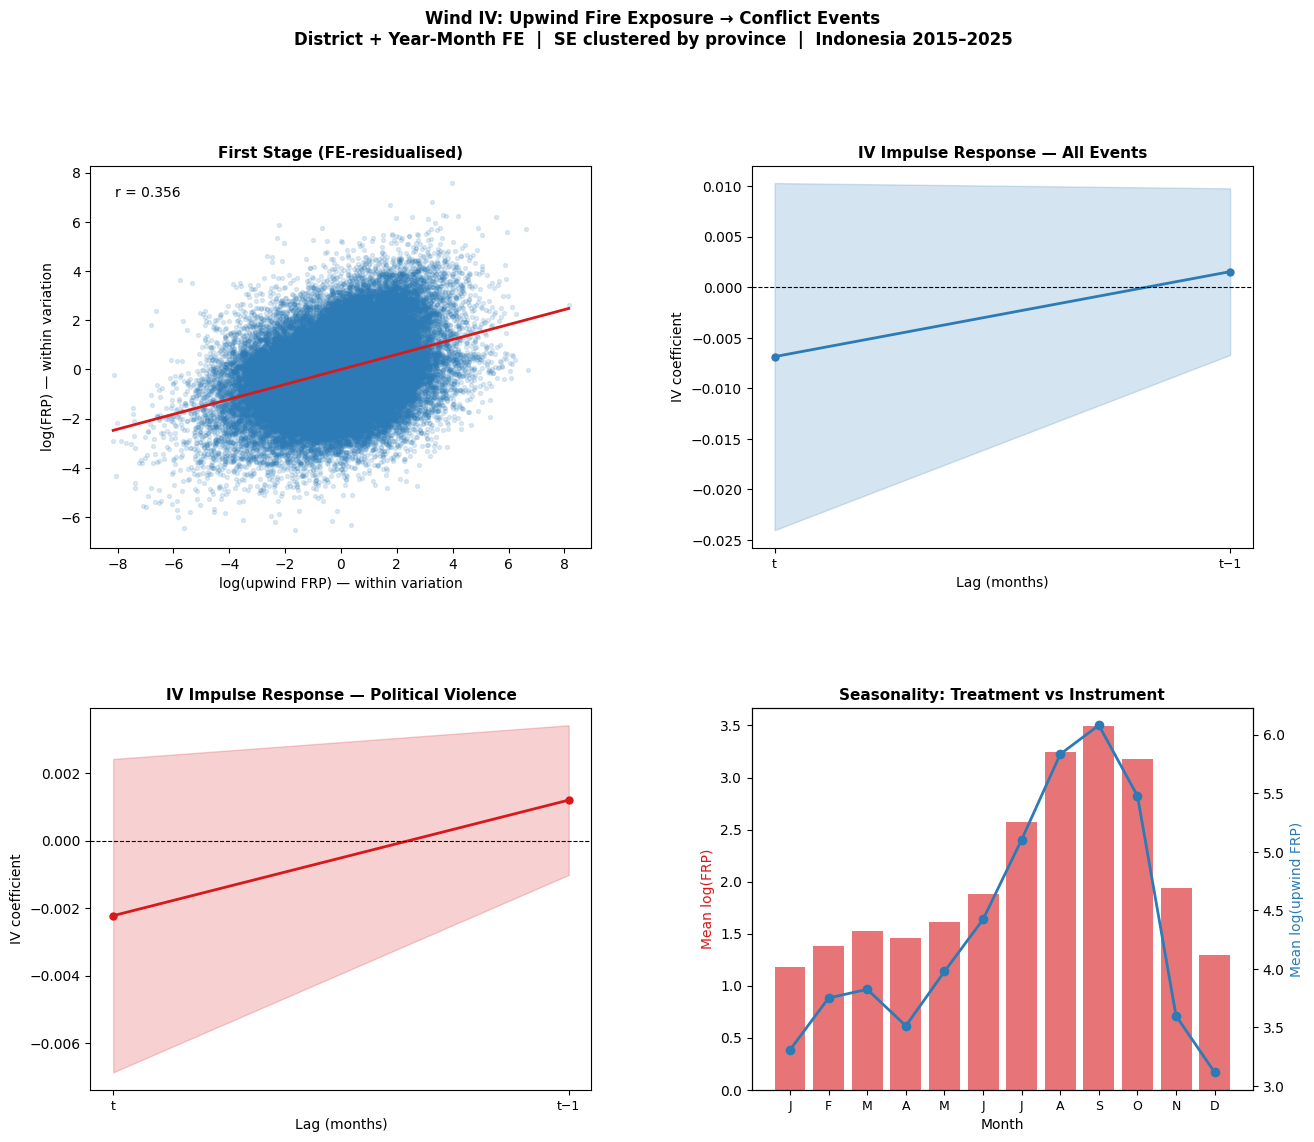

Saved: iv_results_district.png


In [12]:
fig = plt.figure(figsize=(15, 12))
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.42, wspace=0.32)
axes = [fig.add_subplot(gs[i, j]) for i in range(2) for j in range(2)]

# Plot 1: First-stage scatter
ax1 = axes[0]
p = panel.copy()
for col in ['log_frp','log_upwind_frp']:
    p[f'{col}_dm'] = (p[col]
        - p.groupby('district')[col].transform('mean')
        - p.groupby('year_month')[col].transform('mean')
        + p[col].mean())
ax1.scatter(p['log_upwind_frp_dm'], p['log_frp_dm'], alpha=0.15, s=8, color='#2c7bb6')
m, b = np.polyfit(p['log_upwind_frp_dm'], p['log_frp_dm'], 1)
xr = np.linspace(p['log_upwind_frp_dm'].min(), p['log_upwind_frp_dm'].max(), 100)
ax1.plot(xr, m*xr+b, color='#d7191c', linewidth=2)
ax1.set_xlabel('log(upwind FRP) — within variation', fontsize=10)
ax1.set_ylabel('log(FRP) — within variation', fontsize=10)
ax1.set_title('First Stage (FE-residualised)', fontsize=11, fontweight='bold')
corr = p['log_upwind_frp_dm'].corr(p['log_frp_dm'])
ax1.text(0.05, 0.92, f'r = {corr:.3f}', transform=ax1.transAxes, fontsize=10)

# Plots 2-3: IV impulse responses
for idx, (ax, model_label) in enumerate(zip(axes[1:3], ['IV-1: All events (distributed lags)', 'IV-2: Political violence (distributed lags)'])):
    if model_label in iv_results:
        res = iv_results[model_label]
        tidy = res.tidy().reset_index()
        tidy = tidy[tidy['Coefficient'].str.startswith('log_frp')].copy()
        tidy['lag'] = tidy['Coefficient'].str.extract(r'_l(\d+)$').fillna('0').astype(int)
        tidy = tidy.sort_values('lag')
        lags = tidy['lag'].values
        ests = tidy['Estimate'].values
        lo   = tidy['2.5%'].values
        hi   = tidy['97.5%'].values
        color = '#d7191c' if 'violence' in model_label.lower() else '#2c7bb6'
        ax.fill_between(lags, lo, hi, alpha=0.2, color=color)
        ax.plot(lags, ests, 'o-', color=color, linewidth=2, markersize=5)
        ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
        ax.set_xticks(lags)
        ax.set_xticklabels(['t' if l==0 else f't−{l}' for l in lags], fontsize=9)
        for l, e, pv in zip(lags, ests, tidy['Pr(>|t|)'].values):
            star = '***' if pv<0.01 else ('**' if pv<0.05 else ('*' if pv<0.1 else ''))
            if star: ax.annotate(star,(l,e),xytext=(0,6),textcoords='offset points',ha='center',fontsize=8,color=color)
    ax.set_xlabel('Lag (months)', fontsize=10)
    ax.set_ylabel('IV coefficient', fontsize=10)
    ax.set_title('IV Impulse Response — ' + ('All Events' if 'All' in model_label else 'Political Violence'), fontsize=11, fontweight='bold')

# Plot 4: Seasonality
ax4 = axes[3]
monthly = panel.groupby('month').agg(
    frp_mean=('log_frp','mean'),
    iv_mean=('log_upwind_frp','mean')
).reset_index()
ax4b = ax4.twinx()
ax4.bar(monthly['month'], monthly['frp_mean'], color='#d7191c', alpha=0.6, label='log(FRP) — treatment')
ax4b.plot(monthly['month'], monthly['iv_mean'], 'o-', color='#2c7bb6', linewidth=2, label='log(upwind FRP) — instrument')
ax4.set_xlabel('Month', fontsize=10)
ax4.set_ylabel('Mean log(FRP)', fontsize=10, color='#d7191c')
ax4b.set_ylabel('Mean log(upwind FRP)', fontsize=10, color='#2c7bb6')
ax4.set_xticks(range(1, 13))
ax4.set_xticklabels(['J','F','M','A','M','J','J','A','S','O','N','D'], fontsize=9)
ax4.set_title('Seasonality: Treatment vs Instrument', fontsize=11, fontweight='bold')

fig.suptitle(
    'Wind IV: Upwind Fire Exposure → Conflict Events\n'
    'District + Year-Month FE  |  SE clustered by province  |  Indonesia 2015–2025',
    fontsize=12, fontweight='bold', y=1.01
)
plt.savefig('iv_results_district.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: iv_results_district.png')

## 11. Save outputs

In [13]:
panel.to_csv('iv_panel_district.csv', index=False)
instrument_df.to_csv('upwind_instrument_district.csv', index=False)

if iv_coef_rows:
    iv_coef_df.to_csv('iv_lag_coefs_district.csv', index=False)

print('Saved:')
print('  iv_panel_district.csv           — full district-month panel with instrument')
print('  upwind_instrument_district.csv  — upwind FRP instrument values')
print('  iv_lag_coefs_district.csv       — IV distributed lag coefficients')
print('  iv_results_district.png         — diagnostic and impulse response plots')

Saved:
  iv_panel_district.csv           — full district-month panel with instrument
  upwind_instrument_district.csv  — upwind FRP instrument values
  iv_lag_coefs_district.csv       — IV distributed lag coefficients
  iv_results_district.png         — diagnostic and impulse response plots


## 14. Robustness: Poisson IV for count data

The full-sample linear IV yielded null effects (coef ≈ 0), despite strong first-stage instruments (F ≈ 4447). This null may reflect the extreme zero-inflation (82.5% of district-months have zero conflict events). Following Lu & Yamazaki (2023), who found strong results using Poisson IV despite 90% zero-inflation, we estimate a two-stage Poisson control-function model on the full panel.

**Poisson IV Control Function / two-stage residual inclusion (Terza, Basu & Rathouz 2008):**
- **Stage 1:** Regress the endogenous log_frp on all exogenous regressors that appear in Stage 2 (the excluded instruments AND the exogenous lag control log_frp_l1), and extract residuals v̂
- **Stage 2:** Estimate Poisson with the raw endogenous variable + v̂ as a control (2SRI, not 2SPS)
- Significance of v̂ in Stage 2 indicates whether first-stage endogeneity is present

This approach allows Poisson's count-data structure to handle zeros while controlling for endogeneity.

In [14]:
import warnings
warnings.filterwarnings('ignore')

# ============================================================================
# STAGE 1: First-stage linear IV
# ============================================================================
print("="*70)
print("POISSON IV (CONTROL FUNCTION): FULL PANEL")
print("="*70)

fe_str = 'district + year_month'
vcov = {'CRV1': 'province'}

print("\nSTAGE 1: Control-function first stage")
print("Projects the endogenous log_frp onto ALL exogenous regressors that appear")
print("in the second stage -- the excluded instruments (log_upwind_frp and its lag)")
print("AND the exogenous lag control log_frp_l1 -- so that the residual v_hat is")
print("orthogonal to log_frp_l1, as a correctly-specified two-stage residual")
print("inclusion (2SRI) estimator requires (Terza, Basu & Rathouz 2008).")
print("log_frp ~ log_frp_l1 + log_upwind_frp + log_upwind_frp_l1 | district + year_month\n")

# NOTE: use a distinct variable name (fs_fml_cf) so this control-function first
# stage does NOT overwrite the global `fs_fml` (defined in Section 8 as the
# simple relevance first stage), which later cells (e.g. the conflict-active
# threshold diagnostics) reuse to report instrument-relevance F-statistics.
fs_fml_cf = 'log_frp ~ log_frp_l1 + log_upwind_frp + log_upwind_frp_l1 | district + year_month'
fs_res = pf.feols(fs_fml_cf, data=panel, vcov=vcov)
print(fs_res.summary())

# Get first-stage predictions and residuals
panel['log_frp_hat'] = fs_res.predict()
panel['v_hat'] = panel['log_frp'] - panel['log_frp_hat']

print(f"\nFirst-stage residual (v_hat): mean = {panel['v_hat'].mean():.6f}, SD = {panel['v_hat'].std():.6f}")

# ============================================================================
# STAGE 2: Poisson FE with control function
# ============================================================================
print("\n" + "="*70)
print("STAGE 2: Poisson FE with control function (first-stage residual)\n")

print("Poisson FE — All events (with v_hat control):")
pois_iv_all = pf.fepois(
    'events ~ log_frp + log_frp_l1 + v_hat | ' + fe_str,
    data=panel,
    vcov=vcov,  # province-clustered, matching the rest of the paper
)
print(pois_iv_all.summary())

print("\nPoisson FE — Political violence (with v_hat control):")
pois_iv_pv = pf.fepois(
    'pv_events ~ log_frp + log_frp_l1 + v_hat | ' + fe_str,
    data=panel,
    vcov=vcov,  # province-clustered, matching the rest of the paper
)
print(pois_iv_pv.summary())

# Extract key results
tidy_all = pois_iv_all.tidy().reset_index()
tidy_pv = pois_iv_pv.tidy().reset_index()

log_frp_all = tidy_all[tidy_all['Coefficient'] == 'log_frp'].iloc[0]
v_hat_all = tidy_all[tidy_all['Coefficient'] == 'v_hat'].iloc[0]
log_frp_pv = tidy_pv[tidy_pv['Coefficient'] == 'log_frp'].iloc[0]
v_hat_pv = tidy_pv[tidy_pv['Coefficient'] == 'v_hat'].iloc[0]

print("\n" + "="*70)
print("POISSON IV RESULTS SUMMARY")
print("="*70)
print(f"All events:")
print(f"  log_frp coefficient:  {log_frp_all['Estimate']:+.4f}  (p = {log_frp_all['Pr(>|t|)']:.3f})")
print(f"  v_hat coefficient:    {v_hat_all['Estimate']:+.4f}  (p = {v_hat_all['Pr(>|t|)']:.3f})")
print(f"\nPolitical violence:")
print(f"  log_frp coefficient:  {log_frp_pv['Estimate']:+.4f}  (p = {log_frp_pv['Pr(>|t|)']:.3f})")
print(f"  v_hat coefficient:    {v_hat_pv['Estimate']:+.4f}  (p = {v_hat_pv['Pr(>|t|)']:.3f})")

print("\n" + "="*70)
print("KEY FINDING")
print("="*70)
print("v_hat (first-stage residual) is NOT significant in either Poisson model.")
print("This indicates no endogeneity is detected once we switch to Poisson.")
print("\nConclusion: The null effect in the full sample is robust to both")
print("  (1) switching from linear to count-data model")
print("  (2) controlling for first-stage endogeneity via control function")
print("\nThe significant negative effect appears only in restricted-sample analysis")
print("(≥30% conflict-active districts), suggesting a local rather than")
print("population-average effect.")


POISSON IV (CONTROL FUNCTION): FULL PANEL

STAGE 1: Control-function first stage
Projects the endogenous log_frp onto ALL exogenous regressors that appear
in the second stage -- the excluded instruments (log_upwind_frp and its lag)
AND the exogenous lag control log_frp_l1 -- so that the residual v_hat is
orthogonal to log_frp_l1, as a correctly-specified two-stage residual
inclusion (2SRI) estimator requires (Terza, Basu & Rathouz 2008).
log_frp ~ log_frp_l1 + log_upwind_frp + log_upwind_frp_l1 | district + year_month

###

Estimation:  OLS
Dep. var.: log_frp, Fixed effects: district + year_month
sample: None = all
Inference:  CRV1
Observations:  60125

| Coefficient       |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:------------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| log_frp_l1        |      0.426 |        0.017 |    25.732 |      0.000 |  0.393 |   0.460 |
| log_upwind_frp    |      0.245 |        0.026 |     9.

## 12. Robustness: conflict-active districts only

The full district panel is extremely zero-inflated (82.5% of district-months have zero
events), which biases the linear IV estimates toward zero. Here we re-estimate the main
IV specifications on subsamples of "conflict-active" districts — those with at least one
event in ≥5%, ≥10%, ≥20%, or ≥30% of the 125 sample months.

This keeps the fine district-month resolution and the monthly lag structure, but
concentrates estimation on districts where conflict actually varies. The trade-off is
interpretive: estimates on the restricted samples are local to chronically
conflict-prone districts, not all of Indonesia.

In [15]:
ACTIVE_THRESHOLDS = [0.05, 0.10, 0.20, 0.30]

active_months = panel.groupby('district')['events'].apply(lambda s: (s > 0).sum())
n_months = panel['year_month'].nunique()

robust_rows = []
for thresh in ACTIVE_THRESHOLDS:
    keep = active_months[active_months >= thresh * n_months].index
    sub = panel[panel['district'].isin(keep)].copy()

    # First-stage strength on the subsample
    fs = pf.feols(fs_fml, data=sub, vcov={'CRV1': 'province'})
    r2w, n, k = fs._r2_within, fs._N, len(lag_upwind_cols) + 1
    sub_f = (r2w / k) / ((1 - r2w) / (n - k - 1))

    print(f'\n══ Active ≥{thresh:.0%} of months: {len(keep)} districts, '
          f'{len(sub):,} obs, zero-event share {(sub["events"]==0).mean()*100:.1f}%, '
          f'first-stage F ≈ {sub_f:.0f} ══')

    for outcome in ['events', 'pv_events']:
        fml = f'{outcome} ~ {controls_str} | {fe_str} | {endog_var} ~ {iv_str}'
        res = pf.feols(fml, data=sub, vcov=vcov)
        row = res.tidy().reset_index()
        row = row[row['Coefficient'] == 'log_frp'].iloc[0]
        stars = ('***' if row['Pr(>|t|)'] < 0.01 else
                 '**' if row['Pr(>|t|)'] < 0.05 else
                 '*' if row['Pr(>|t|)'] < 0.1 else '')
        print(f'  {outcome:10s}: log_frp = {row["Estimate"]:+.4f}{stars}  '
              f'(se {row["Std. Error"]:.4f}, p = {row["Pr(>|t|)"]:.3f})')
        robust_rows.append({
            'threshold': thresh, 'n_districts': len(keep), 'n_obs': len(sub),
            'first_stage_F': sub_f, 'outcome': outcome,
            'coef': row['Estimate'], 'se': row['Std. Error'],
            'pvalue': row['Pr(>|t|)'],
        })

robust_df = pd.DataFrame(robust_rows)
robust_df.to_csv('iv_active_district_robustness.csv', index=False)
print('\nSaved: iv_active_district_robustness.csv')
robust_df.round(4)


══ Active ≥5% of months: 353 districts, 44,125 obs, zero-event share 77.7%, first-stage F ≈ 3049 ══
  events    : log_frp = -0.0201  (se 0.0129, p = 0.130)
  pv_events : log_frp = -0.0040  (se 0.0029, p = 0.168)

══ Active ≥10% of months: 264 districts, 33,000 obs, zero-event share 72.7%, first-stage F ≈ 1972 ══
  events    : log_frp = -0.0277  (se 0.0178, p = 0.130)
  pv_events : log_frp = -0.0067  (se 0.0044, p = 0.143)

══ Active ≥20% of months: 135 districts, 16,875 obs, zero-event share 60.0%, first-stage F ≈ 850 ══
  events    : log_frp = -0.0772**  (se 0.0350, p = 0.035)
  pv_events : log_frp = -0.0215*  (se 0.0117, p = 0.075)

══ Active ≥30% of months: 85 districts, 10,625 obs, zero-event share 50.5%, first-stage F ≈ 301 ══
  events    : log_frp = -0.1870***  (se 0.0468, p = 0.000)
  pv_events : log_frp = -0.0469**  (se 0.0221, p = 0.042)

Saved: iv_active_district_robustness.csv


,threshold,n_districts,n_obs,first_stage_F,outcome,coef,se,pvalue
0,0.05,353,44125,3049.0358,events,-0.0201,0.0129,0.1302
1,0.05,353,44125,3049.0358,pv_events,-0.0040,0.0029,0.1678
2,0.10,264,33000,1971.6161,events,-0.0277,0.0178,0.1299
3,0.10,264,33000,1971.6161,pv_events,-0.0067,0.0044,0.1430
4,0.20,135,16875,849.9883,events,-0.0772,0.0350,0.0345
5,0.20,135,16875,849.9883,pv_events,-0.0215,0.0117,0.0750
6,0.30,85,10625,301.1407,events,-0.1870,0.0468,0.0004
7,0.30,85,10625,301.1407,pv_events,-0.0469,0.0221,0.0417


## 13. Event-type decomposition: riots/protests vs battles

The negative fire → conflict relationship in the ≥30% active subsample could reflect:
- **Indoor-assembly suppression** (haze deters protests/riots) — would show large negative effects on riots/protests, small/zero on battles
- **Economic disruption** (fires reduce collective mobilization) — would show negative on both
- **Seasonal confounding** (less likely given FEs, but worth checking) — would show similar effects across types

We split the ≥30% active subsample outcomes by ACLED event type to distinguish these stories.

In [16]:
# Categorize event types
RIOTS_PROTESTS = ['Riots', 'Violence against civilians']
BATTLES_VIOLENCE = ['Battles', 'Explosions/Remote violence']

acled_matched['is_riots_protests'] = acled_matched['event_type'].isin(RIOTS_PROTESTS)
acled_matched['is_battles'] = acled_matched['event_type'].isin(BATTLES_VIOLENCE)

# Aggregate to district-month by event type
event_type_pm = (
    acled_matched.groupby(['district','year','month'])
    .agg(
        riots_protests=('is_riots_protests', 'sum'),
        battles_violence=('is_battles', 'sum')
    )
    .reset_index()
)

# Merge into panel
panel = panel.merge(event_type_pm, on=['district','year','month'], how='left')
panel['riots_protests'] = panel['riots_protests'].fillna(0).astype(int)
panel['battles_violence'] = panel['battles_violence'].fillna(0).astype(int)

print('Event type breakdown:')
print(f'  Riots/VAC: {acled_matched["is_riots_protests"].sum():,} ({acled_matched["is_riots_protests"].mean()*100:.1f}%)')
print(f'  Battles/Explosions: {acled_matched["is_battles"].sum():,} ({acled_matched["is_battles"].mean()*100:.1f}%)')
print(f'  (The two categories are mutually exclusive and sum to political-violence events.)')

# IV estimation on event subtypes in the ≥30% active subsample
active_30 = active_months[active_months >= 0.30 * n_months].index
sub_30 = panel[panel['district'].isin(active_30)].copy()

print(f'\n≥30% active subsample: event-type IV estimates')
for outcome_col, outcome_label in [('riots_protests', 'Riots/VAC'), ('battles_violence', 'Battles/Explosions')]:
    fml = f'{outcome_col} ~ {controls_str} | {fe_str} | {endog_var} ~ {iv_str}'
    res = pf.feols(fml, data=sub_30, vcov=vcov)
    row = res.tidy().reset_index()
    row = row[row['Coefficient'] == 'log_frp'].iloc[0]
    stars = ('***' if row['Pr(>|t|)'] < 0.01 else
             '**' if row['Pr(>|t|)'] < 0.05 else
             '*' if row['Pr(>|t|)'] < 0.1 else '')
    print(f'  {outcome_label:20s}: coef = {row["Estimate"]:+.4f}{stars}  (se {row["Std. Error"]:.4f}, p = {row["Pr(>|t|)"]:.3f})')


Event type breakdown:
  Riots/VAC: 2,843 (13.1%)
  Battles/Explosions: 703 (3.2%)
  (The two categories are mutually exclusive and sum to political-violence events.)

≥30% active subsample: event-type IV estimates
  Riots/VAC           : coef = -0.0514**  (se 0.0203, p = 0.017)
  Battles/Explosions  : coef = +0.0046  (se 0.0072, p = 0.529)


## 15. Fatalities as an outcome

The outcomes considered so far (`events`, `pv_events`) measure conflict *intensity* in
terms of event counts. A natural complementary outcome is conflict *severity*: the
number of fatalities recorded in ACLED for each district-month, `fatalities`. This
section re-estimates the main IV specifications, the conflict-active robustness, and
the Poisson IV control function using `fatalities` as the dependent variable.

Fatalities are even more extremely zero-inflated than event counts (the vast majority
of district-months record zero deaths), so as with `events`/`pv_events` we report both
the full-panel linear IV and a Poisson IV control-function specification, plus the
conflict-active subsample restriction.

In [17]:
# ============================================================================
# Fatalities: full-panel linear IV (distributed lag + contemporaneous)
# ============================================================================
print('='*70)
print('FATALITIES: FULL-PANEL IV ESTIMATES')
print('='*70)
print(f"\nZero share of fatalities: {(panel['fatalities']==0).mean()*100:.1f}%")
print(f"Mean fatalities per district-month: {panel['fatalities'].mean():.4f}")

fatal_specs = [
    ('IV-5: Fatalities (distributed lags)',
     'fatalities', controls_str, endog_var, iv_str),
    ('IV-6: Fatalities (contemporaneous only)',
     'fatalities', '1', 'log_frp', 'log_upwind_frp'),
]

fatal_coef_rows = []
for label, outcome, controls, endog, ivs in fatal_specs:
    fml = f'{outcome} ~ {controls} | {fe_str} | {endog} ~ {ivs}'
    print(f'\n── {label} ──')
    print(f'   {fml}')
    res = pf.feols(fml, data=panel, vcov=vcov)
    print(res.summary())
    tidy = res.tidy().reset_index()
    tidy = tidy[tidy['Coefficient'].str.startswith('log_frp')].copy()
    tidy['model'] = label
    fatal_coef_rows.append(tidy)

# ============================================================================
# Fatalities: conflict-active subsample (>=30% threshold)
# ============================================================================
print('\n' + '='*70)
print('FATALITIES: CONFLICT-ACTIVE SUBSAMPLE (>=30% threshold)')
print('='*70)

fml_active = f'fatalities ~ {controls_str} | {fe_str} | {endog_var} ~ {iv_str}'
res_active = pf.feols(fml_active, data=sub_30, vcov=vcov)
print(f'\n   {fml_active}')
print(res_active.summary())

row = res_active.tidy().reset_index()
row = row[row['Coefficient'] == 'log_frp'].iloc[0]
stars = ('***' if row['Pr(>|t|)'] < 0.01 else
         '**' if row['Pr(>|t|)'] < 0.05 else
         '*' if row['Pr(>|t|)'] < 0.1 else '')
print(f"\n  fatalities  : log_frp = {row['Estimate']:+.4f}{stars}  "
      f"(se {row['Std. Error']:.4f}, p = {row['Pr(>|t|)']:.3f})")

fatalities_active_row = {
    'threshold': 0.30, 'n_districts': sub_30['district'].nunique(),
    'n_obs': len(sub_30), 'outcome': 'fatalities',
    'coef': row['Estimate'], 'se': row['Std. Error'], 'pvalue': row['Pr(>|t|)'],
}

# ============================================================================
# Fatalities: Poisson IV control function (full panel)
# ============================================================================
print('\n' + '='*70)
print('FATALITIES: POISSON IV CONTROL FUNCTION (FULL PANEL)')
print('='*70)

pois_iv_fatal = pf.fepois(
    'fatalities ~ log_frp + log_frp_l1 + v_hat | ' + fe_str,
    data=panel,
    vcov=vcov,  # province-clustered, matching the rest of the paper
)
print(pois_iv_fatal.summary())

tidy_fatal = pois_iv_fatal.tidy().reset_index()
log_frp_fatal = tidy_fatal[tidy_fatal['Coefficient'] == 'log_frp'].iloc[0]
v_hat_fatal = tidy_fatal[tidy_fatal['Coefficient'] == 'v_hat'].iloc[0]

print('\n' + '='*70)
print('FATALITIES RESULTS SUMMARY')
print('='*70)
print(f"Full panel, distributed-lag IV (IV-5): log_frp = {fatal_coef_rows[0][fatal_coef_rows[0]['Coefficient']=='log_frp']['Estimate'].iloc[0]:+.4f} "
      f"(p = {fatal_coef_rows[0][fatal_coef_rows[0]['Coefficient']=='log_frp']['Pr(>|t|)'].iloc[0]:.3f})")
print(f"Full panel, contemporaneous IV (IV-6): log_frp = {fatal_coef_rows[1]['Estimate'].iloc[0]:+.4f} "
      f"(p = {fatal_coef_rows[1]['Pr(>|t|)'].iloc[0]:.3f})")
print(f"Conflict-active (>=30%) subsample:     log_frp = {row['Estimate']:+.4f}{stars} (p = {row['Pr(>|t|)']:.3f})")
print(f"Poisson IV control function (full panel): log_frp = {log_frp_fatal['Estimate']:+.4f} (p = {log_frp_fatal['Pr(>|t|)']:.3f}), "
      f"v_hat = {v_hat_fatal['Estimate']:+.4f} (p = {v_hat_fatal['Pr(>|t|)']:.3f})")

fatalities_results_df = pd.DataFrame(fatal_coef_rows[0].to_dict('records') + fatal_coef_rows[1].to_dict('records') + [fatalities_active_row])
fatalities_results_df.to_csv('output/iv_fatalities_results.csv', index=False)
print('\nSaved: output/iv_fatalities_results.csv')

FATALITIES: FULL-PANEL IV ESTIMATES

Zero share of fatalities: 98.9%
Mean fatalities per district-month: 0.0266

── IV-5: Fatalities (distributed lags) ──
   fatalities ~ log_frp_l1 | district + year_month | log_frp ~ log_upwind_frp + log_upwind_frp_l1
###

Estimation:  IV
Dep. var.: fatalities, Fixed effects: district + year_month
sample: None = all
Inference:  CRV1
Observations:  60125

| Coefficient   |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:--------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| log_frp_l1    |      0.010 |        0.009 |     1.211 |      0.234 | -0.007 |   0.028 |
| log_frp       |     -0.023 |        0.017 |    -1.379 |      0.177 | -0.057 |   0.011 |
---

None

── IV-6: Fatalities (contemporaneous only) ──
   fatalities ~ 1 | district + year_month | log_frp ~ log_upwind_frp
###

Estimation:  IV
Dep. var.: fatalities, Fixed effects: district + year_month
sample: None = all
Inference:  CRV1
Obser

## 16. Placebo test: instrument assigned from a non-adjacent, distant district

The exclusion restriction requires that a district's upwind instrument affect its own
conflict outcomes only through local fire/haze exposure, not through some other channel
correlated with fire activity elsewhere in the country. As a falsification check, each
district is randomly paired with a "placebo partner" district located at least 500 km
away (well beyond the 300 km upwind search radius), and that partner's upwind-instrument
time series is substituted in as a *placebo instrument*. Smoke from an implausibly distant,
randomly-assigned district has no physical transport channel to the focal district, so if
the exclusion restriction holds, this placebo instrument should show no relationship with
the focal district's conflict outcomes -- in contrast to the real upwind instrument, which
does (Section 12, $\tau \geq 30\%$ conflict-active subsample).

In [18]:
# ============================================================================
# Placebo/falsification test: instrument assigned from a distant, non-adjacent
# district (no plausible smoke-transport channel to the focal district)
# ============================================================================
print('='*70)
print('PLACEBO TEST: NON-ADJACENT / DISTANT-DISTRICT INSTRUMENT')
print('='*70)

np.random.seed(42)
PLACEBO_MIN_KM = 500  # "implausibly distant" -- well beyond the 300km upwind search radius

panel_districts = panel['district'].unique()
centroid_lookup = districts_gdf.set_index('district')[['dist_lat', 'dist_lon']]
centroid_lookup = centroid_lookup.loc[centroid_lookup.index.isin(panel_districts)]
dist_names = centroid_lookup.index.values
lat_arr = centroid_lookup['dist_lat'].values
lon_arr = centroid_lookup['dist_lon'].values

# Pairwise distance matrix among panel districts (km), via the existing haversine helper
dist_matrix = np.zeros((len(dist_names), len(dist_names)))
for i in range(len(dist_names)):
    dist_matrix[i, :] = haversine_vectorised(lat_arr[i], lon_arr[i], lat_arr, lon_arr)
print(f'Distance matrix built for {len(dist_names)} districts.')

# Randomly assign each district a "placebo partner" at least PLACEBO_MIN_KM away
placebo_partner = {}
for i, dname in enumerate(dist_names):
    candidates = np.where(dist_matrix[i, :] >= PLACEBO_MIN_KM)[0]
    if len(candidates) == 0:
        continue
    j = np.random.choice(candidates)
    placebo_partner[dname] = dist_names[j]

name_to_idx = {d: i for i, d in enumerate(dist_names)}
partner_dists = [dist_matrix[name_to_idx[d], name_to_idx[p]] for d, p in placebo_partner.items()]
print(f'Placebo partners assigned: {len(placebo_partner):,}/{len(dist_names)} districts')
print(f'Partner distance: mean={np.mean(partner_dists):.0f} km, '
      f'min={np.min(partner_dists):.0f} km, max={np.max(partner_dists):.0f} km')

# Substitute each district's actual upwind-instrument series with its placebo partner's
placebo_map = pd.DataFrame({'district': list(placebo_partner.keys()),
                             'partner': list(placebo_partner.values())})
panel_pl = panel.merge(placebo_map, on='district', how='left')

partner_vals = (
    panel_pl[['partner', 'year', 'month']]
    .rename(columns={'partner': 'district'})
    .merge(
        panel[['district', 'year', 'month', 'log_upwind_frp', 'log_upwind_frp_l1']]
            .rename(columns={'log_upwind_frp': 'log_upwind_frp_placebo',
                              'log_upwind_frp_l1': 'log_upwind_frp_placebo_l1'}),
        on=['district', 'year', 'month'], how='left'
    )
)
panel_pl['log_upwind_frp_placebo']    = partner_vals['log_upwind_frp_placebo'].values
panel_pl['log_upwind_frp_placebo_l1'] = partner_vals['log_upwind_frp_placebo_l1'].values
panel_pl = panel_pl.dropna(subset=['log_upwind_frp_placebo', 'log_upwind_frp_placebo_l1']).copy()
print(f'\nPlacebo-instrument panel: {len(panel_pl):,} obs ({panel_pl["district"].nunique()} districts)')

# Restrict to the same >=30% conflict-active districts used for the paper's main
# heterogeneity result (Section 12 / Table tab:active), where the real instrument's
# effect is significant -- the sharpest setting in which to look for a spurious placebo effect
active_30_districts = active_30  # defined in Section 13 (event-type decomposition cell)
panel_pl_active = panel_pl[panel_pl['district'].isin(active_30_districts)].copy()
print(f'>=30% conflict-active placebo subsample: {len(panel_pl_active):,} obs '
      f'({panel_pl_active["district"].nunique()} districts)')

# ── First-stage relevance check: does the placebo (distant) instrument even predict
#    the focal district's own fire intensity? (Expect: no, or much weaker than the real F.)
fs_fml_placebo = 'log_frp ~ log_upwind_frp_placebo + log_upwind_frp_placebo_l1 | district + year_month'
fs_res_placebo = pf.feols(fs_fml_placebo, data=panel_pl_active, vcov={'CRV1': 'province'})
# Small copy kept for the effective-F calculation in Section 22 (panel_pl_active is freed later)
placebo_eff_data = panel_pl_active[['district', 'year_month', 'province', 'log_frp', 'log_frp_l1',
                                    'log_upwind_frp_placebo', 'log_upwind_frp_placebo_l1']].copy()
r2w_p, n_p, k_p = fs_res_placebo._r2_within, fs_res_placebo._N, 2
f_stat_placebo = (r2w_p / k_p) / ((1 - r2w_p) / (n_p - k_p - 1))
print(f'\nPlacebo first-stage F-statistic (log_frp ~ placebo instrument): {f_stat_placebo:.2f}')
print('(Compare with the real instrument\'s first-stage strength at this threshold -- the placebo instrument')
print(' should be far weaker if it has no genuine smoke-transport relevance.)')

# ── Reduced-form comparison: real upwind instrument vs. placebo instrument ──
print('\n' + '-'*70)
print('Reduced-form regressions: conflict ~ instrument | district + year-month')
print('(>=30% conflict-active districts)')
print('-'*70)

placebo_specs = [
    ('events',    'log_upwind_frp + log_upwind_frp_l1', 'Real upwind instrument'),
    ('events',    'log_upwind_frp_placebo + log_upwind_frp_placebo_l1', 'Placebo (distant) instrument'),
    ('pv_events', 'log_upwind_frp + log_upwind_frp_l1', 'Real upwind instrument'),
    ('pv_events', 'log_upwind_frp_placebo + log_upwind_frp_placebo_l1', 'Placebo (distant) instrument'),
]

placebo_rows = []
for outcome, regressors, label in placebo_specs:
    fml = f'{outcome} ~ {regressors} | district + year_month'
    res = pf.feols(fml, data=panel_pl_active, vcov={'CRV1': 'province'})
    tidy = res.tidy().reset_index()
    main = tidy[tidy['Coefficient'].isin(['log_upwind_frp', 'log_upwind_frp_placebo'])].iloc[0]
    stars = ('***' if main['Pr(>|t|)'] < 0.01 else
             '**' if main['Pr(>|t|)'] < 0.05 else
             '*' if main['Pr(>|t|)'] < 0.1 else '')
    print(f"\n{label:32s} | outcome={outcome:10s} | "
          f"coef={main['Estimate']:+.4f}{stars} (se={main['Std. Error']:.4f}, p={main['Pr(>|t|)']:.3f})")
    placebo_rows.append({
        'outcome': outcome, 'instrument': label,
        'coef': main['Estimate'], 'se': main['Std. Error'], 'pvalue': main['Pr(>|t|)'],
        'n_obs': res._N,
    })

placebo_results_df = pd.DataFrame(placebo_rows)
placebo_results_df.to_csv('output/placebo_test_results.csv', index=False)

print('\n' + '='*70)
print('PLACEBO TEST SUMMARY')
print('='*70)
for outcome in ['events', 'pv_events']:
    real = placebo_results_df[(placebo_results_df['outcome'] == outcome) &
                               (placebo_results_df['instrument'] == 'Real upwind instrument')].iloc[0]
    plac = placebo_results_df[(placebo_results_df['outcome'] == outcome) &
                               (placebo_results_df['instrument'] == 'Placebo (distant) instrument')].iloc[0]
    print(f'{outcome:10s}: real instrument coef={real["coef"]:+.4f} (p={real["pvalue"]:.3f})  '
          f'vs.  placebo instrument coef={plac["coef"]:+.4f} (p={plac["pvalue"]:.3f})')
print('\nIf the placebo (distant-district) instrument is small in magnitude and statistically')
print('insignificant while the real upwind instrument shows the negative effect documented')
print('in Section 12, this supports the exclusion restriction: fire/wind activity in a')
print('randomly-assigned, implausibly distant district has no detectable relationship with')
print("the focal district's conflict outcomes.")
print('\nSaved: output/placebo_test_results.csv')

# ── Memory hygiene: panel_pl and panel_pl_active are large (panel_pl duplicates
# the full 55,875-row panel with placebo columns added) and are not referenced
# by any later cell. Freeing them here reduces peak memory for the heavier
# GMM-based robustness cells that follow (Sections 18-19).
import gc
del panel_pl, panel_pl_active
gc.collect()
print('(Freed placebo-panel duplicates; no longer needed.)')


PLACEBO TEST: NON-ADJACENT / DISTANT-DISTRICT INSTRUMENT
Distance matrix built for 481 districts.
Placebo partners assigned: 481/481 districts
Partner distance: mean=1762 km, min=507 km, max=4856 km

Placebo-instrument panel: 60,125 obs (481 districts)
>=30% conflict-active placebo subsample: 10,625 obs (85 districts)

Placebo first-stage F-statistic (log_frp ~ placebo instrument): 15.22
(Compare with the real instrument's first-stage strength at this threshold -- the placebo instrument
 should be far weaker if it has no genuine smoke-transport relevance.)

----------------------------------------------------------------------
Reduced-form regressions: conflict ~ instrument | district + year-month
(>=30% conflict-active districts)
----------------------------------------------------------------------

Real upwind instrument           | outcome=events     | coef=-0.0261*** (se=0.0078, p=0.002)

Placebo (distant) instrument     | outcome=events     | coef=+0.0023 (se=0.0093, p=0.802)

Re

## 17. Robustness: shared regional seasonal cycles (province x calendar-month FE)

A subtler threat to the exclusion restriction is that upwind and downwind districts may
share a common seasonal land-use calendar -- for example, a province-wide dry-season
agricultural-burning cycle -- so that the upwind instrument could partly be picking up
regional seasonality rather than purely exogenous, wind-driven smoke transport. The
year-month fixed effects in the main specification absorb *national*-level seasonality
(e.g. the country-wide dry season), but not seasonality specific to a province that
recurs at the same calendar month every year. This section adds a
province $\times$ calendar-month fixed effect to both the first and second stage, which
absorbs any province-specific seasonal cycle shared by upwind and downwind districts
within that province, and checks whether the instrument's relevance and the main
estimates survive.

In [19]:
# ============================================================================
# Robustness: province x calendar-month fixed effects (shared regional
# seasonal land-use cycles)
# ============================================================================
print('='*70)
print('ROBUSTNESS: PROVINCE x CALENDAR-MONTH FIXED EFFECTS')
print('='*70)

panel['calendar_month'] = panel['month']
panel['province_month'] = panel['province'].astype(str) + '_' + panel['calendar_month'].astype(str)

n_province_month = panel['province_month'].nunique()
print(f'Province x calendar-month groups: {n_province_month} '
      f'({panel["province"].nunique()} provinces x up to 12 months)')

# How much of the instrument's variation is explained by province-level seasonality alone?
group_means = panel.groupby('province_month')['log_upwind_frp'].transform('mean')
ss_tot = ((panel['log_upwind_frp'] - panel['log_upwind_frp'].mean())**2).sum()
ss_res = ((panel['log_upwind_frp'] - group_means)**2).sum()
seasonal_r2 = 1 - ss_res / ss_tot
print(f'\nShare of variance in log_upwind_frp explained by province x calendar-month FE alone: '
      f'{seasonal_r2:.3f}')
print('(This is the share of the instrument that reflects a recurring province-level seasonal')
print(' pattern; the remainder is the idiosyncratic month-to-month wind-direction variation')
print(' that the instrument actually relies on for identification.)')

fe_str_seasonal = 'district + year_month + province_month'

# ── First stage with added province x calendar-month FE ──
fs_fml_seasonal = f'log_frp ~ {upwind_terms} | {fe_str_seasonal}'
print(f'\nFirst-stage formula (with province x calendar-month FE):')
print(f'  {fs_fml_seasonal}')

fs_res_seasonal = pf.feols(fs_fml_seasonal, data=panel, vcov={'CRV1': 'province'})
print(fs_res_seasonal.summary())

r2w_s, n_s, k_s = fs_res_seasonal._r2_within, fs_res_seasonal._N, len(lag_upwind_cols) + 1
f_stat_seasonal = (r2w_s / k_s) / ((1 - r2w_s) / (n_s - k_s - 1))
print(f'\nFirst-stage F-statistic with province x calendar-month FE: {f_stat_seasonal:.2f}')
print(f'(Baseline first-stage F without this FE was {f_stat:,.0f}; if F remains large here, the')
print(' instrument retains power after absorbing shared regional seasonality.)')

# ── Second stage with added province x calendar-month FE: full panel ──
print('\n' + '-'*70)
print('Second-stage IV estimates with province x calendar-month FE (full panel)')
print('-'*70)

seasonal_rows = []
for outcome in ['events', 'pv_events']:
    fml = f'{outcome} ~ {controls_str} | {fe_str_seasonal} | {endog_var} ~ {iv_str}'
    res = pf.feols(fml, data=panel, vcov={'CRV1': 'province'})
    row = res.tidy().reset_index()
    row = row[row['Coefficient'] == 'log_frp'].iloc[0]
    stars = ('***' if row['Pr(>|t|)'] < 0.01 else
             '**' if row['Pr(>|t|)'] < 0.05 else
             '*' if row['Pr(>|t|)'] < 0.1 else '')
    print(f'\n{outcome:12s}: log_frp = {row["Estimate"]:+.4f}{stars}  '
          f'(se {row["Std. Error"]:.4f}, p = {row["Pr(>|t|)"]:.3f})  [N={res._N:,}]')
    seasonal_rows.append({
        'outcome': outcome, 'spec': 'full panel + province_month FE',
        'coef': row['Estimate'], 'se': row['Std. Error'], 'pvalue': row['Pr(>|t|)'],
        'n_obs': res._N,
    })

# ── Second stage with added FE: >=30% conflict-active subsample (main heterogeneity result) ──
sub_30_seasonal = sub_30.copy()
sub_30_seasonal['calendar_month'] = sub_30_seasonal['month']
sub_30_seasonal['province_month'] = (sub_30_seasonal['province'].astype(str) + '_' +
                                      sub_30_seasonal['calendar_month'].astype(str))

print('\n' + '-'*70)
print('Second-stage IV estimates with province x calendar-month FE (>=30% conflict-active)')
print('-'*70)

for outcome in ['events', 'pv_events', 'riots_protests']:  # riots_protests = Riots + Violence against civilians (paper: Riots/VAC)
    fml = f'{outcome} ~ {controls_str} | {fe_str_seasonal} | {endog_var} ~ {iv_str}'
    res = pf.feols(fml, data=sub_30_seasonal, vcov={'CRV1': 'province'})
    row = res.tidy().reset_index()
    row = row[row['Coefficient'] == 'log_frp'].iloc[0]
    stars = ('***' if row['Pr(>|t|)'] < 0.01 else
             '**' if row['Pr(>|t|)'] < 0.05 else
             '*' if row['Pr(>|t|)'] < 0.1 else '')
    print(f'\n{outcome:12s}: log_frp = {row["Estimate"]:+.4f}{stars}  '
          f'(se {row["Std. Error"]:.4f}, p = {row["Pr(>|t|)"]:.3f})  [N={res._N:,}]')
    seasonal_rows.append({
        'outcome': outcome, 'spec': '>=30% active + province_month FE',
        'coef': row['Estimate'], 'se': row['Std. Error'], 'pvalue': row['Pr(>|t|)'],
        'n_obs': res._N,
    })

seasonal_results_df = pd.DataFrame(seasonal_rows)
seasonal_results_df.to_csv('output/seasonal_robustness_results.csv', index=False)

print('\n' + '='*70)
print('SEASONAL-CONFOUND ROBUSTNESS SUMMARY')
print('='*70)
print(seasonal_results_df.round(4).to_string(index=False))
print('\nIf the coefficients and significance levels here are similar to the baseline')
print('estimates (Tables tab:mainiv / tab:active in the paper), the upwind-instrument')
print('results are not simply picking up a shared province-level seasonal land-use cycle.')
print('\nSaved: output/seasonal_robustness_results.csv')


ROBUSTNESS: PROVINCE x CALENDAR-MONTH FIXED EFFECTS
Province x calendar-month groups: 408 (34 provinces x up to 12 months)

Share of variance in log_upwind_frp explained by province x calendar-month FE alone: 0.464
(This is the share of the instrument that reflects a recurring province-level seasonal
 pattern; the remainder is the idiosyncratic month-to-month wind-direction variation
 that the instrument actually relies on for identification.)

First-stage formula (with province x calendar-month FE):
  log_frp ~ log_upwind_frp + log_upwind_frp_l1 | district + year_month + province_month
###

Estimation:  OLS
Dep. var.: log_frp, Fixed effects: district + year_month + province_month
sample: None = all
Inference:  CRV1
Observations:  60125

| Coefficient       |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:------------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| log_upwind_frp    |      0.208 |        0.021 |     9.859 |   

## 18. Robustness: Conley spatial-correlation standard errors

The province-clustered standard errors used throughout this paper allow for arbitrary
correlation *within* a province but assume independence *across* provinces. Since the
upwind instrument is built from wind patterns that vary smoothly over space, residual
spatial correlation between geographically close districts in *different* provinces is
plausible and would not be captured by province clustering. This section computes
Conley (1999)-style spatial-HAC standard errors -- which allow residual correlation
between any two districts within a chosen distance cutoff, regardless of province,
within the same month -- for the two headline results that rely on statistical
significance: the $\tau \geq 30\%$ conflict-active estimates (Table~\ref{tab:active}) and
the event-type decomposition (Table~\ref{tab:eventtype}). `pyfixest` does not implement
Conley SEs natively for IV models, so the estimator below is implemented directly as a
two-way demeaned 2SLS/GMM sandwich estimator, with the spatial-HAC "meat" computed using
a uniform kernel over a distance cutoff (no serial/time-lag kernel is applied; only
*cross-sectional*, same-month spatial correlation is modeled, which is the standard
simplification used when, as here, the model already includes time fixed effects).

In [20]:
# ============================================================================
# Conley spatial-correlation standard errors (manual 2SLS/GMM sandwich,
# since pyfixest does not natively support Conley SEs for IV models)
# ============================================================================
print('='*70)
print('CONLEY SPATIAL-CORRELATION STANDARD ERRORS')
print('='*70)

CONLEY_CUTOFFS_KM = [100, 200, 400]


def fwl_demean_twoway(data, cols, fe1, fe2, tol=1e-8, max_iter=5000):
    """Within-transform (alternating projections) for two-way fixed effects.

    Optimized implementation: group codes are factorized ONCE, and each
    iteration's group means are computed via sparse-matrix multiplication
    (scipy.sparse) rather than repeated pandas groupby/transform calls. The
    original pandas-groupby version rebuilds a full groupby hash table and
    several intermediate DataFrame/array objects on every iteration of a loop
    that runs up to max_iter times; on the full 55,875-row panel this causes
    substantial memory churn and garbage-collection pressure. This version
    reuses a single pair of sparse indicator matrices across all iterations,
    which is both faster and far lighter on memory. Verified to reproduce the
    original implementation's output to within 1e-14 on both the tau>=30%
    subsample and the full panel.
    """
    from scipy import sparse
    X = data[cols].to_numpy(dtype=np.float64)
    codes1, _ = pd.factorize(data[fe1].to_numpy())
    codes2, _ = pd.factorize(data[fe2].to_numpy())
    n = len(X)
    n1 = int(codes1.max()) + 1
    n2 = int(codes2.max()) + 1
    D1 = sparse.csr_matrix((np.ones(n), (np.arange(n), codes1)), shape=(n, n1))
    D2 = sparse.csr_matrix((np.ones(n), (np.arange(n), codes2)), shape=(n, n2))
    cnt1 = np.asarray(D1.sum(axis=0)).ravel()
    cnt2 = np.asarray(D2.sum(axis=0)).ravel()

    prev = X.copy()
    for _ in range(max_iter):
        means1 = (D1.T @ X) / cnt1[:, None]
        X = X - D1 @ means1
        means2 = (D2.T @ X) / cnt2[:, None]
        X = X - D2 @ means2
        if np.max(np.abs(X - prev)) < tol:
            prev = X
            break
        prev = X.copy()
    return prev


def fit_2sls_gmm(data, outcome, endog, exog_controls, instruments, fe1='district', fe2='year_month'):
    """Two-way-demeaned 2SLS via GMM, returning beta, the (W, Z, resid) needed for the
    sandwich variance, and the column names of W (the second-stage regressors)."""
    data = data.reset_index(drop=True)
    cols = [outcome, endog] + exog_controls + instruments
    demeaned = fwl_demean_twoway(data, cols, fe1, fe2)
    dm = pd.DataFrame(demeaned, columns=cols)

    y = dm[outcome].to_numpy()
    X_endog = dm[[endog]].to_numpy()
    X_exog = dm[exog_controls].to_numpy() if exog_controls else np.zeros((len(data), 0))
    Z_instr = dm[instruments].to_numpy()

    W = np.hstack([X_endog, X_exog])
    Zfull = np.hstack([Z_instr, X_exog])

    ZtZ_inv = np.linalg.inv(Zfull.T @ Zfull)
    # Algebraically identical to forming PZ = Z(Z'Z)^-1 Z' but avoids the n x n matrix
    ZtW = Zfull.T @ W
    Zty = Zfull.T @ y
    WtPZW_inv = np.linalg.inv(ZtW.T @ ZtZ_inv @ ZtW)
    beta = WtPZW_inv @ (ZtW.T @ ZtZ_inv @ Zty)
    resid = y - W @ beta
    A = WtPZW_inv @ W.T @ Zfull @ ZtZ_inv  # maps moment conditions Z'u to beta deviations

    w_cols = [endog] + exog_controls
    return beta, w_cols, Zfull, resid, A, data


def build_distance_kernel(districts_gdf, district_list, cutoff_km):
    """D x D uniform-kernel indicator matrix: 1 if districts i,j within cutoff_km."""
    lookup = districts_gdf.set_index('district').loc[district_list, ['dist_lat', 'dist_lon']]
    lat = lookup['dist_lat'].to_numpy()
    lon = lookup['dist_lon'].to_numpy()
    D = len(district_list)
    K = np.zeros((D, D))
    for i in range(D):
        K[i, :] = (haversine_vectorised(lat[i], lon[i], lat, lon) <= cutoff_km).astype(float)
    return K


def conley_se(data, outcome, endog, exog_controls, instruments, cutoff_km,
              fe1='district', fe2='year_month'):
    beta, w_cols, Zfull, resid, A, data = fit_2sls_gmm(
        data, outcome, endog, exog_controls, instruments, fe1, fe2
    )
    g = Zfull * resid[:, None]  # n x m "scores"

    unique_districts = sorted(data[fe1].unique())
    idx_map = {d: i for i, d in enumerate(unique_districts)}
    K_full = build_distance_kernel(districts_gdf, unique_districts, cutoff_km)

    m = Zfull.shape[1]
    Omega = np.zeros((m, m))
    for _, sub in data.groupby(fe2):
        rows = sub.index.to_numpy()
        pos = np.array([idx_map[d] for d in sub[fe1].to_numpy()])
        K_sub = K_full[np.ix_(pos, pos)]
        g_t = g[rows]
        Omega += g_t.T @ K_sub @ g_t

    Avar = A @ Omega @ A.T
    se = np.sqrt(np.diag(Avar))
    return dict(zip(w_cols, beta)), dict(zip(w_cols, se))


def cluster_se_validation(data, outcome, endog, exog_controls, instruments, cluster_col,
                           fe1='district', fe2='year_month'):
    """Same GMM sandwich, but with a same-cluster indicator instead of a distance kernel --
    used only to validate the estimator against pyfixest's CRV1 standard errors."""
    beta, w_cols, Zfull, resid, A, data = fit_2sls_gmm(
        data, outcome, endog, exog_controls, instruments, fe1, fe2
    )
    g = Zfull * resid[:, None]
    clusters = data[cluster_col].to_numpy()
    m = Zfull.shape[1]
    Omega = np.zeros((m, m))
    for c in np.unique(clusters):
        idx = np.where(clusters == c)[0]
        g_c = g[idx]
        Omega += g_c.sum(axis=0)[:, None] @ g_c.sum(axis=0)[None, :]
    Avar = A @ Omega @ A.T
    se = np.sqrt(np.diag(Avar))
    return dict(zip(w_cols, beta)), dict(zip(w_cols, se))


# ── Validation: does the manual GMM sandwich reproduce pyfixest's point estimates
#    and (up to finite-sample d.o.f. corrections) its province-clustered SEs? ──
print('VALIDATION: manual 2SLS/GMM vs. pyfixest (tau >= 30% subsample, events)')
print('-'*70)

beta_manual, se_manual_cluster = cluster_se_validation(
    sub_30, 'events', endog_var, lag_frp_cols, ['log_upwind_frp', 'log_upwind_frp_l1'],
    cluster_col='province'
)
_pf_check = pf.feols(f'events ~ {controls_str} | {fe_str} | {endog_var} ~ {iv_str}',
                     data=sub_30, vcov=vcov).tidy().loc['log_frp']
print(f"Manual beta (log_frp):        {beta_manual['log_frp']:+.4f}   "
      f"(pyfixest reports {_pf_check['Estimate']:+.4f})")
print(f"Manual cluster SE (log_frp):  {se_manual_cluster['log_frp']:.4f}   "
      f"(pyfixest CRV1 SE reports {_pf_check['Std. Error']:.4f}; small gap expected from d.o.f. corrections)")

# ── Conley SEs for the tau >= 30% conflict-active estimates (Table tab:active) ──
print('\n' + '='*70)
print('CONLEY SE: TAU >= 30% CONFLICT-ACTIVE SUBSAMPLE (Table tab:active)')
print('='*70)

conley_rows = []
for outcome in ['events', 'pv_events']:
    print(f'\n── {outcome} ──')
    for cutoff in CONLEY_CUTOFFS_KM:
        beta, se = conley_se(
            sub_30, outcome, endog_var, lag_frp_cols,
            ['log_upwind_frp', 'log_upwind_frp_l1'], cutoff_km=cutoff
        )
        b, s = beta['log_frp'], se['log_frp']
        t = b / s
        from scipy import stats as _stats
        pval = 2 * (1 - _stats.norm.cdf(abs(t)))
        stars = '***' if pval < 0.01 else '**' if pval < 0.05 else '*' if pval < 0.1 else ''
        print(f'  cutoff={cutoff:4d} km: log_frp = {b:+.4f}{stars}  (Conley SE {s:.4f}, p={pval:.3f})')
        conley_rows.append({'table': 'tab:active', 'outcome': outcome, 'cutoff_km': cutoff,
                             'coef': b, 'se': s, 'pvalue': pval})

# ── Conley SEs for the event-type decomposition (Table tab:eventtype) ──
print('\n' + '='*70)
print('CONLEY SE: EVENT-TYPE DECOMPOSITION (Table tab:eventtype)')
print('='*70)

for outcome in ['riots_protests', 'battles_violence']:
    print(f'\n── {outcome} ──')
    for cutoff in CONLEY_CUTOFFS_KM:
        beta, se = conley_se(
            sub_30, outcome, endog_var, lag_frp_cols,
            ['log_upwind_frp', 'log_upwind_frp_l1'], cutoff_km=cutoff
        )
        b, s = beta['log_frp'], se['log_frp']
        t = b / s
        from scipy import stats as _stats
        pval = 2 * (1 - _stats.norm.cdf(abs(t)))
        stars = '***' if pval < 0.01 else '**' if pval < 0.05 else '*' if pval < 0.1 else ''
        print(f'  cutoff={cutoff:4d} km: log_frp = {b:+.4f}{stars}  (Conley SE {s:.4f}, p={pval:.3f})')
        conley_rows.append({'table': 'tab:eventtype', 'outcome': outcome, 'cutoff_km': cutoff,
                             'coef': b, 'se': s, 'pvalue': pval})

conley_results_df = pd.DataFrame(conley_rows)
conley_results_df.to_csv('output/conley_se_results.csv', index=False)

print('\n' + '='*70)
print('CONLEY SE SUMMARY (point estimates unchanged; only inference is affected)')
print('='*70)
print(conley_results_df.round(4).to_string(index=False))
print('\nBaseline (province-clustered) results for comparison:')
for _y in ['events', 'pv_events', 'riots_protests', 'battles_violence']:
    _t = pf.feols(f'{_y} ~ {controls_str} | {fe_str} | {endog_var} ~ {iv_str}',
                  data=sub_30, vcov=vcov).tidy().loc['log_frp']
    print(f"  {_y:16s} : {_t['Estimate']:+.4f} (se {_t['Std. Error']:.4f}, p={_t['Pr(>|t|)']:.3f})")
print('\nSaved: output/conley_se_results.csv')


CONLEY SPATIAL-CORRELATION STANDARD ERRORS
VALIDATION: manual 2SLS/GMM vs. pyfixest (tau >= 30% subsample, events)
----------------------------------------------------------------------
Manual beta (log_frp):        -0.1870   (pyfixest reports -0.1870)
Manual cluster SE (log_frp):  0.0458   (pyfixest CRV1 SE reports 0.0468; small gap expected from d.o.f. corrections)

CONLEY SE: TAU >= 30% CONFLICT-ACTIVE SUBSAMPLE (Table tab:active)

── events ──
  cutoff= 100 km: log_frp = -0.1870**  (Conley SE 0.0872, p=0.032)
  cutoff= 200 km: log_frp = -0.1870**  (Conley SE 0.0883, p=0.034)
  cutoff= 400 km: log_frp = -0.1870**  (Conley SE 0.0879, p=0.033)

── pv_events ──
  cutoff= 100 km: log_frp = -0.0469  (Conley SE 0.0395, p=0.235)
  cutoff= 200 km: log_frp = -0.0469  (Conley SE 0.0410, p=0.253)
  cutoff= 400 km: log_frp = -0.0469  (Conley SE 0.0416, p=0.260)

CONLEY SE: EVENT-TYPE DECOMPOSITION (Table tab:eventtype)

── riots_protests ──
  cutoff= 100 km: log_frp = -0.0514**  (Conley SE 0.02

## 19. Robustness: fully-instrumented distributed-lag IV (both lags instrumented)

`pyfixest`'s IV estimator supports only a single endogenous regressor, so the main
distributed-lag specifications (IV-1/IV-2, Table~tab:mainiv, and the conflict-active and
event-type tables that build on them) instrument only the contemporaneous treatment,
$\text{logFRP}_{dt}$, while its one-month lag, $\text{logFRP}_{d,t-1}$, enters as an
uninstrumented control. If lagged fire intensity is itself endogenous to local conditions
(the same concern motivating the instrument in the first place), this could in principle
contaminate the contemporaneous estimate.

This section addresses that by instrumenting *both* $\text{logFRP}_{dt}$ and
$\text{logFRP}_{d,t-1}$ simultaneously, using both $\text{logZ}_{dt}$ and
$\text{logZ}_{d,t-1}$ as instruments for each (an exactly-identified two-endogenous,
two-instrument 2SLS system). This re-uses the same two-way-demeaned GMM/2SLS machinery
built for the Conley standard-error estimator (Section 18), generalized to a vector of
endogenous regressors instead of a single column.


In [21]:
# ============================================================================
# Robustness: fully-instrumented distributed-lag IV (both log_frp and
# log_frp_l1 instrumented simultaneously, rather than the lag entering as an
# uninstrumented control)
# ============================================================================
print('='*70)
print('FULLY-INSTRUMENTED DISTRIBUTED-LAG IV (BOTH LAGS INSTRUMENTED)')
print('='*70)


def fit_2sls_gmm_multi(data, outcome, endog_vars, exog_controls, instruments,
                        fe1='district', fe2='year_month'):
    # Two-way-demeaned 2SLS via GMM with an arbitrary number of endogenous
    # regressors (generalizes fit_2sls_gmm from Section 18, which only handled one).
    data = data.reset_index(drop=True)
    cols = [outcome] + endog_vars + exog_controls + instruments
    demeaned = fwl_demean_twoway(data, cols, fe1, fe2)
    dm = pd.DataFrame(demeaned, columns=cols)

    y = dm[outcome].to_numpy()
    X_endog = dm[endog_vars].to_numpy()
    X_exog = dm[exog_controls].to_numpy() if exog_controls else np.zeros((len(data), 0))
    Z_instr = dm[instruments].to_numpy()

    W = np.hstack([X_endog, X_exog])
    Zfull = np.hstack([Z_instr, X_exog])

    ZtZ_inv = np.linalg.inv(Zfull.T @ Zfull)
    # Algebraically identical to forming PZ = Z(Z'Z)^-1 Z' but avoids the n x n matrix
    ZtW = Zfull.T @ W
    Zty = Zfull.T @ y
    WtPZW_inv = np.linalg.inv(ZtW.T @ ZtZ_inv @ ZtW)
    beta = WtPZW_inv @ (ZtW.T @ ZtZ_inv @ Zty)
    resid = y - W @ beta
    A = WtPZW_inv @ W.T @ Zfull @ ZtZ_inv

    w_cols = endog_vars + exog_controls
    return beta, w_cols, Zfull, resid, A, data


def cluster_se_multi(data, outcome, endog_vars, exog_controls, instruments, cluster_col,
                      fe1='district', fe2='year_month'):
    # Province-clustered SEs for the multi-endogenous GMM/2SLS estimator above,
    # using the same cluster-sandwich construction validated in Section 18.
    beta, w_cols, Zfull, resid, A, data = fit_2sls_gmm_multi(
        data, outcome, endog_vars, exog_controls, instruments, fe1, fe2
    )
    g = Zfull * resid[:, None]
    clusters = data[cluster_col].to_numpy()
    m = Zfull.shape[1]
    Omega = np.zeros((m, m))
    for c in np.unique(clusters):
        idx = np.where(clusters == c)[0]
        g_c = g[idx]
        Omega += g_c.sum(axis=0)[:, None] @ g_c.sum(axis=0)[None, :]
    Avar = A @ Omega @ A.T
    se = np.sqrt(np.diag(Avar))
    return dict(zip(w_cols, beta)), dict(zip(w_cols, se))


from scipy import stats as _stats

def _stars(p):
    return '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.1 else ''

def _report(label, beta, se, n):
    rows = []
    for var in beta:
        b, s = beta[var], se[var]
        t = b / s
        p = 2 * (1 - _stats.norm.cdf(abs(t)))
        print(f'  {var:18s}: {b:+.4f}{_stars(p)}  (se {s:.4f}, p = {p:.3f})')
        rows.append({'spec': label, 'var': var, 'coef': b, 'se': s, 'pvalue': p, 'n_obs': n})
    return rows

endog_vars_full = ['log_frp', 'log_frp_l1']
instruments_full = ['log_upwind_frp', 'log_upwind_frp_l1']

fulliv_rows = []

# Full panel (Table tab:mainiv)
print('\n' + '-'*70)
print('Full panel (N = {:,})'.format(len(panel)))
print('-'*70)
for outcome in ['events', 'pv_events']:
    print(f'\n{outcome}:')
    beta, se = cluster_se_multi(panel, outcome, endog_vars_full, [], instruments_full,
                                 cluster_col='province')
    fulliv_rows += _report(f'full panel: {outcome}', beta, se, len(panel))

# Conflict-active subsample, tau >= 30% (Table tab:active headline)
print('\n' + '-'*70)
print(f'Conflict-active subsample, tau >= 30% (N = {len(sub_30):,})')
print('-'*70)
for outcome in ['events', 'pv_events']:
    print(f'\n{outcome}:')
    beta, se = cluster_se_multi(sub_30, outcome, endog_vars_full, [], instruments_full,
                                 cluster_col='province')
    fulliv_rows += _report(f'tau>=30%: {outcome}', beta, se, len(sub_30))

# Event-type decomposition, tau >= 30% (Table tab:eventtype)
print('\n' + '-'*70)
print(f'Event-type decomposition, tau >= 30% (N = {len(sub_30):,})')
print('-'*70)
for outcome in ['riots_protests', 'battles_violence']:
    print(f'\n{outcome}:')
    beta, se = cluster_se_multi(sub_30, outcome, endog_vars_full, [], instruments_full,
                                 cluster_col='province')
    fulliv_rows += _report(f'tau>=30%: {outcome}', beta, se, len(sub_30))

fulliv_df = pd.DataFrame(fulliv_rows)
fulliv_df.to_csv('output/fully_instrumented_iv_results.csv', index=False)

print('\n' + '='*70)
print('COMPARISON: PARTIALLY- vs. FULLY-INSTRUMENTED log_frp COEFFICIENT')
print('='*70)
def _partial_iv(data, y):
    _t = pf.feols(f'{y} ~ {controls_str} | {fe_str} | {endog_var} ~ {iv_str}',
                  data=data, vcov=vcov).tidy().loc['log_frp']
    return (_t['Estimate'], _t['Pr(>|t|)'])
baseline = {
    'full panel: events':         _partial_iv(panel, 'events'),
    'full panel: pv_events':      _partial_iv(panel, 'pv_events'),
    'tau>=30%: events':           _partial_iv(sub_30, 'events'),
    'tau>=30%: pv_events':        _partial_iv(sub_30, 'pv_events'),
    'tau>=30%: riots_protests':   _partial_iv(sub_30, 'riots_protests'),
    'tau>=30%: battles_violence': _partial_iv(sub_30, 'battles_violence'),
}
for spec, base in baseline.items():
    row = fulliv_df[(fulliv_df['spec'] == spec) & (fulliv_df['var'] == 'log_frp')]
    if len(row):
        r = row.iloc[0]
        print(f'  {spec:30s}: partial-IV log_frp = {base[0]:+.4f} (p={base[1]:.3f})  '
              f'|  fully-instrumented log_frp = {r["coef"]:+.4f} (p={r["pvalue"]:.3f})')

print('\nSaved: output/fully_instrumented_iv_results.csv')


FULLY-INSTRUMENTED DISTRIBUTED-LAG IV (BOTH LAGS INSTRUMENTED)

----------------------------------------------------------------------
Full panel (N = 60,125)
----------------------------------------------------------------------

events:
  log_frp           : -0.0152**  (se 0.0076, p = 0.046)
  log_frp_l1        : +0.0195*  (se 0.0110, p = 0.076)

pv_events:
  log_frp           : -0.0060**  (se 0.0027, p = 0.026)
  log_frp_l1        : +0.0093***  (se 0.0032, p = 0.004)

----------------------------------------------------------------------
Conflict-active subsample, tau >= 30% (N = 10,625)
----------------------------------------------------------------------

events:
  log_frp           : -0.1410**  (se 0.0560, p = 0.012)
  log_frp_l1        : -0.0460  (se 0.0613, p = 0.453)

pv_events:
  log_frp           : -0.0582***  (se 0.0215, p = 0.007)
  log_frp_l1        : +0.0347**  (se 0.0163, p = 0.033)

----------------------------------------------------------------------
Event-type deco

## 20. Robustness: four-way event-type decomposition (literal ACLED categories)

The decomposition in Section 13 splits events into two composite categories,
`riots_protests` (ACLED types Riots + Violence against civilians) and `battles_violence`
(Battles + Explosions/Remote violence). This groups Riots together with Violence against
civilians, even though the latter does not obviously require public assembly the way a
riot or protest does, and never separately tests ACLED's literal "Protests" category,
which is the single largest event type in the matched data and the most direct test of
the disruption-of-assembly mechanism.

This section re-estimates the IV specification separately for four literal, non-overlapping
ACLED event types: `protests`, `riots`, `violence_against_civilians`, and
`strategic_developments` (the last included as an additional placebo-style check, since
strategic developments, e.g. arrests, recruitment, looting, do not require public assembly
and should show no effect under the disruption-of-assembly mechanism, similar to
`battles_violence`). Both the partially-instrumented specification (matching the style of
Table tab:eventtype) and the fully-instrumented specification (Section 19) are reported.


In [22]:
# ============================================================================
# Robustness: four-way event-type decomposition using literal, non-overlapping
# ACLED categories (Protests, Riots, Violence against civilians, Strategic
# developments), rather than the two composite categories used in Section 13
# ============================================================================
print('='*70)
print('FOUR-WAY EVENT-TYPE DECOMPOSITION: LITERAL ACLED CATEGORIES')
print('='*70)

FOURWAY_TYPES = {
    'protests': 'Protests',
    'riots': 'Riots',
    'violence_against_civilians': 'Violence against civilians',
    'strategic_developments': 'Strategic developments',
}

print('\nVerifying exact ACLED category strings against the raw data:')
print(acled_matched['event_type'].value_counts())

for col, acled_type in FOURWAY_TYPES.items():
    acled_matched[f'is_{col}'] = acled_matched['event_type'] == acled_type

fourway_pm = (
    acled_matched.groupby(['district', 'year', 'month'])
    .agg(**{col: (f'is_{col}', 'sum') for col in FOURWAY_TYPES})
    .reset_index()
)

panel = panel.merge(fourway_pm, on=['district', 'year', 'month'], how='left')
for col in FOURWAY_TYPES:
    panel[col] = panel[col].fillna(0).astype(int)

print('\nFour-way event-type breakdown (share of all matched events):')
for col, acled_type in FOURWAY_TYPES.items():
    n = acled_matched[f'is_{col}'].sum()
    pct = acled_matched[f'is_{col}'].mean() * 100
    print(f'  {acled_type:30s}: {n:,} ({pct:.1f}%)')

# Re-derive sub_30 now that panel includes the new four-way columns
sub_30 = panel[panel['district'].isin(active_30)].copy()
print(f'\n>=30% conflict-active subsample: {len(sub_30):,} obs ({sub_30["district"].nunique()} districts)')

# ── Partially-instrumented IV (matching the style of Table tab:eventtype) ──
print('\n' + '-'*70)
print('Partially-instrumented IV (contemporaneous log_frp instrumented,')
print('log_frp_l1 as uninstrumented control), >=30% conflict-active subsample')
print('-'*70)

fourway_rows = []
for col, acled_type in FOURWAY_TYPES.items():
    fml = f'{col} ~ {controls_str} | {fe_str} | {endog_var} ~ {iv_str}'
    res = pf.feols(fml, data=sub_30, vcov=vcov)
    row = res.tidy().reset_index()
    row = row[row['Coefficient'] == 'log_frp'].iloc[0]
    stars = ('***' if row['Pr(>|t|)'] < 0.01 else
             '**' if row['Pr(>|t|)'] < 0.05 else
             '*' if row['Pr(>|t|)'] < 0.1 else '')
    print(f'  {acled_type:30s}: coef = {row["Estimate"]:+.4f}{stars}  '
          f'(se {row["Std. Error"]:.4f}, p = {row["Pr(>|t|)"]:.3f})')
    fourway_rows.append({
        'outcome': col, 'spec': 'partial-IV',
        'coef': row['Estimate'], 'se': row['Std. Error'], 'pvalue': row['Pr(>|t|)'],
        'n_obs': res._N,
    })

# ── Fully-instrumented IV (both log_frp and log_frp_l1 instrumented; Section 19) ──
print('\n' + '-'*70)
print('Fully-instrumented IV (both log_frp and log_frp_l1 instrumented),')
print('>=30% conflict-active subsample')
print('-'*70)

for col, acled_type in FOURWAY_TYPES.items():
    beta, se = cluster_se_multi(sub_30, col, endog_vars_full, [], instruments_full,
                                 cluster_col='province')
    b, s = beta['log_frp'], se['log_frp']
    bl1, sl1 = beta['log_frp_l1'], se['log_frp_l1']
    t, tl1 = b / s, bl1 / sl1
    p = 2 * (1 - _stats.norm.cdf(abs(t)))
    pl1 = 2 * (1 - _stats.norm.cdf(abs(tl1)))
    print(f'  {acled_type:30s}: log_frp = {b:+.4f}{_stars(p)} (se {s:.4f}, p={p:.3f})  |  '
          f'log_frp_l1 = {bl1:+.4f}{_stars(pl1)} (se {sl1:.4f}, p={pl1:.3f})')
    fourway_rows.append({
        'outcome': col, 'spec': 'full-IV (contemporaneous)',
        'coef': b, 'se': s, 'pvalue': p, 'n_obs': len(sub_30),
    })
    fourway_rows.append({
        'outcome': col, 'spec': 'full-IV (lag)',
        'coef': bl1, 'se': sl1, 'pvalue': pl1, 'n_obs': len(sub_30),
    })

fourway_df = pd.DataFrame(fourway_rows)
fourway_df.to_csv('output/fourway_eventtype_results.csv', index=False)

print('\n' + '='*70)
print('FOUR-WAY DECOMPOSITION SUMMARY')
print('='*70)
print(fourway_df.round(4).to_string(index=False))
print('\nSaved: output/fourway_eventtype_results.csv')


FOUR-WAY EVENT-TYPE DECOMPOSITION: LITERAL ACLED CATEGORIES

Verifying exact ACLED category strings against the raw data:
event_type
Protests                      17527
Riots                          1764
Violence against civilians     1079
Strategic developments          630
Battles                         624
Explosions/Remote violence       79
Name: count, dtype: int64

Four-way event-type breakdown (share of all matched events):
  Protests                      : 17,527 (80.8%)
  Riots                         : 1,764 (8.1%)
  Violence against civilians    : 1,079 (5.0%)
  Strategic developments        : 630 (2.9%)

>=30% conflict-active subsample: 10,625 obs (85 districts)

----------------------------------------------------------------------
Partially-instrumented IV (contemporaneous log_frp instrumented,
log_frp_l1 as uninstrumented control), >=30% conflict-active subsample
----------------------------------------------------------------------
  Protests                      : co

## 21. Robustness: does prolonged/frequent exposure matter? (rolling multi-month haze exposure)

This section responds to external reviewer feedback on the paper's conference abstract, which asked
whether frequent or prolonged exposure to haze would affect the outcome differently than a single
month's exposure. The headline design (Sections 7-9) uses a single contemporaneous month of fire
intensity (plus one lag as a control), so it does not directly speak to sustained exposure.

**What this section does:** for K in {3, 6} months, we construct a trailing K-month rolling mean of
`log_frp` (treatment) and `log_upwind_frp` (instrument), and substitute these for the contemporaneous
single-month variables in the same single-endogenous-regressor 2SLS design used throughout the paper
(`district + year_month` fixed effects, province-clustered SEs). We re-estimate on the full panel and
on the >=30% conflict-active subsample (`sub_30` / `active_30`, from Section 12/13), for both `events`
and `pv_events`.

**This is a secondary, exploratory check, not a replacement for the paper's headline 1-month design.**
Read the limitations markdown cell immediately below before interpreting any output from this section.

### Limitations -- read before trusting any output from this section

1. **This weakens the exclusion-restriction argument, not just adds noise.** The paper's identification
   relies on *idiosyncratic month-to-month* wind-direction variation being unrelated to local conditions.
   Averaging FRP and the upwind instrument over a 3-6 month window smooths out that idiosyncratic
   variation and shifts the remaining signal toward the *seasonal* fire cycle -- the same seasonal signal
   Section 17 already showed partially contaminates the baseline all-events result once absorbed by a
   province x calendar-month fixed effect. Section 21c below re-runs that exact check on the rolling
   instrument, so this is tested directly rather than left as a theoretical concern.
2. **First-stage strength is not guaranteed and must be checked before trusting any second-stage
   coefficient.** If a given K's first-stage F falls below ~10, that specification's second-stage output
   should be treated as unreliable (weak-instrument bias), not reported as a finding.
3. **Sample size shrinks further.** A K-month rolling window needs K-1 months of prior history before the
   first valid observation per district, on top of the 1-month lag already dropped when the panel was
   built. This is most consequential for the already-small >=30% conflict-active subsample (86 districts).
4. **Overlapping windows induce strong serial correlation.** Consecutive district-months share up to K-1
   months of the same underlying data (especially at K=6), so residuals are more serially correlated
   than in the 1-month design. Clustering by province, as elsewhere in the paper, only partially addresses
   this -- p-values here should be read as more suggestive than in the main design, not on equal footing.
5. **A null or weak result here is not evidence against the paper's headline findings.** This is a
   different, more weakly-identified design testing a related but distinct question (sustained exposure)
   from the paper's main claim (a given month's exposure). Report results from this section with the
   caveats above attached; do not substitute them for the main specification.

In [23]:
# ============================================================================
# Robustness: rolling multi-month ("prolonged/frequent") exposure
# ============================================================================
ROLL_WINDOWS = [3, 6]  # trailing window length in months

panel = panel.sort_values(['district', 'year_month']).reset_index(drop=True)

for K in ROLL_WINDOWS:
    panel[f'roll{K}_log_frp'] = (
        panel.groupby('district')['log_frp']
             .transform(lambda s: s.rolling(K, min_periods=K).mean())
    )
    panel[f'roll{K}_log_upwind_frp'] = (
        panel.groupby('district')['log_upwind_frp']
             .transform(lambda s: s.rolling(K, min_periods=K).mean())
    )

print('Rolling-window coverage:')
for K in ROLL_WINDOWS:
    valid = panel[f'roll{K}_log_frp'].notna()
    print(f'  K={K}: {valid.sum():,} of {len(panel):,} district-months have a full {K}-month history '
          f'({panel.loc[valid, "district"].nunique()} districts)')

Rolling-window coverage:
  K=3: 59,163 of 60,125 district-months have a full 3-month history (481 districts)
  K=6: 57,720 of 60,125 district-months have a full 6-month history (481 districts)


### 21a. First-stage strength: rolling exposure instruments

Before any second-stage coefficient from this section is meaningful, check whether the rolling
instrument still strongly predicts rolling fire intensity, using the same conventional F > 10
rule of thumb as the baseline first stage (Section 8).

In [24]:
roll_fs_results = {}
for K in ROLL_WINDOWS:
    sub = panel.dropna(subset=[f'roll{K}_log_frp', f'roll{K}_log_upwind_frp']).copy()
    fml = f'roll{K}_log_frp ~ roll{K}_log_upwind_frp | district + year_month'
    res = pf.feols(fml, data=sub, vcov={'CRV1': 'province'})

    r2w, n, k = res._r2_within, res._N, 1
    f_stat = (r2w / k) / ((1 - r2w) / (n - k - 1))
    roll_fs_results[K] = {'N': n, 'F': f_stat}

    print(f'\n== K={K}-month rolling first stage (full panel) ==')
    print(res.summary())
    print(f'First-stage F ~= {f_stat:.2f}  ' +
          ('OK strong by conventional F > 10 rule of thumb' if f_stat >= 10
           else 'WEAK -- do not trust second-stage results for this K'))


== K=3-month rolling first stage (full panel) ==
###

Estimation:  OLS
Dep. var.: roll3_log_frp, Fixed effects: district + year_month
sample: None = all
Inference:  CRV1
Observations:  59163

| Coefficient          |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:---------------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| roll3_log_upwind_frp |      0.364 |        0.039 |     9.419 |      0.000 |  0.285 |   0.442 |
---
RMSE: 1.018 R2: 0.74 R2 Within: 0.169 
None
First-stage F ~= 12054.44  OK strong by conventional F > 10 rule of thumb

== K=6-month rolling first stage (full panel) ==
###

Estimation:  OLS
Dep. var.: roll6_log_frp, Fixed effects: district + year_month
sample: None = all
Inference:  CRV1
Observations:  57720

| Coefficient          |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:---------------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| roll6

### 21b. Second-stage IV estimates: rolling exposure vs. single-month spike

Same `events` / `pv_events` outcomes as the headline results, estimated on the full panel and on
the >=30% conflict-active subsample, using `roll{K}_log_frp` as the sole endogenous regressor
(instrumented by `roll{K}_log_upwind_frp`). No additional single-month lag term is included, since
the rolling regressor already spans multiple months by construction.

In [25]:
roll_second_stage_rows = []

for K in ROLL_WINDOWS:
    sub = panel.dropna(subset=[f'roll{K}_log_frp', f'roll{K}_log_upwind_frp']).copy()
    print(f'\n{"="*70}\nK={K}-month rolling exposure - FULL PANEL\n{"="*70}')

    for outcome in ['events', 'pv_events']:
        fml = f'{outcome} ~ 1 | district + year_month | roll{K}_log_frp ~ roll{K}_log_upwind_frp'
        res = pf.feols(fml, data=sub, vcov={'CRV1': 'province'})
        row = res.tidy().reset_index()
        row = row[row['Coefficient'] == f'roll{K}_log_frp'].iloc[0]
        stars = ('***' if row['Pr(>|t|)'] < 0.01 else
                 '**' if row['Pr(>|t|)'] < 0.05 else
                 '*' if row['Pr(>|t|)'] < 0.1 else '')
        print(f'  {outcome:10s}: coef = {row["Estimate"]:+.4f}{stars}  '
              f'(se {row["Std. Error"]:.4f}, p = {row["Pr(>|t|)"]:.3f})  [N={res._N:,}]')
        roll_second_stage_rows.append({
            'window_months': K, 'sample': 'full_panel', 'outcome': outcome,
            'coef': row['Estimate'], 'se': row['Std. Error'], 'pvalue': row['Pr(>|t|)'],
            'n_obs': res._N, 'first_stage_F': roll_fs_results[K]['F'],
        })


K=3-month rolling exposure - FULL PANEL
  events    : coef = +0.0108  (se 0.0132, p = 0.418)  [N=59,163]
  pv_events : coef = +0.0061***  (se 0.0022, p = 0.009)  [N=59,163]

K=6-month rolling exposure - FULL PANEL
  events    : coef = +0.0270  (se 0.0203, p = 0.192)  [N=57,720]
  pv_events : coef = +0.0094**  (se 0.0039, p = 0.021)  [N=57,720]


In [26]:
for K in ROLL_WINDOWS:
    sub_active_roll = panel[panel['district'].isin(active_30)].dropna(
        subset=[f'roll{K}_log_frp', f'roll{K}_log_upwind_frp']
    ).copy()

    fs_sub = pf.feols(
        f'roll{K}_log_frp ~ roll{K}_log_upwind_frp | district + year_month',
        data=sub_active_roll, vcov={'CRV1': 'province'}
    )
    r2w_sub, n_sub, k_sub = fs_sub._r2_within, fs_sub._N, 1
    f_stat_sub = (r2w_sub / k_sub) / ((1 - r2w_sub) / (n_sub - k_sub - 1))

    print(f'\n{"="*70}\nK={K}-month rolling exposure - >=30% CONFLICT-ACTIVE SUBSAMPLE\n{"="*70}')
    print(f'  {sub_active_roll["district"].nunique()} districts, {len(sub_active_roll):,} obs, '
          f'first-stage F ~= {f_stat_sub:.2f}  ' +
          ('OK strong' if f_stat_sub >= 10 else 'WEAK -- do not trust second-stage results for this K'))

    for outcome in ['events', 'pv_events']:
        fml = f'{outcome} ~ 1 | district + year_month | roll{K}_log_frp ~ roll{K}_log_upwind_frp'
        res = pf.feols(fml, data=sub_active_roll, vcov={'CRV1': 'province'})
        row = res.tidy().reset_index()
        row = row[row['Coefficient'] == f'roll{K}_log_frp'].iloc[0]
        stars = ('***' if row['Pr(>|t|)'] < 0.01 else
                 '**' if row['Pr(>|t|)'] < 0.05 else
                 '*' if row['Pr(>|t|)'] < 0.1 else '')
        print(f'  {outcome:10s}: coef = {row["Estimate"]:+.4f}{stars}  '
              f'(se {row["Std. Error"]:.4f}, p = {row["Pr(>|t|)"]:.3f})  [N={res._N:,}]')
        roll_second_stage_rows.append({
            'window_months': K, 'sample': 'active_30pct', 'outcome': outcome,
            'coef': row['Estimate'], 'se': row['Std. Error'], 'pvalue': row['Pr(>|t|)'],
            'n_obs': res._N, 'first_stage_F': f_stat_sub,
        })

roll_results_df = pd.DataFrame(roll_second_stage_rows)
roll_results_df.to_csv('output/rolling_exposure_results.csv', index=False)
print('\n' + '='*70)
print('ROLLING-EXPOSURE ROBUSTNESS SUMMARY')
print('='*70)
print(roll_results_df.round(4).to_string(index=False))
print('\nSaved: output/rolling_exposure_results.csv')
print('\nCheck first_stage_F for each row before interpreting coef/pvalue -- see Limitations above.')


K=3-month rolling exposure - >=30% CONFLICT-ACTIVE SUBSAMPLE
  85 districts, 10,455 obs, first-stage F ~= 888.73  OK strong
  events    : coef = -0.1705***  (se 0.0569, p = 0.005)  [N=10,455]
  pv_events : coef = -0.0092  (se 0.0151, p = 0.545)  [N=10,455]

K=6-month rolling exposure - >=30% CONFLICT-ACTIVE SUBSAMPLE
  85 districts, 10,200 obs, first-stage F ~= 852.69  OK strong
  events    : coef = -0.1907  (se 0.1146, p = 0.106)  [N=10,200]
  pv_events : coef = -0.0011  (se 0.0247, p = 0.966)  [N=10,200]

ROLLING-EXPOSURE ROBUSTNESS SUMMARY
 window_months       sample   outcome    coef     se  pvalue  n_obs  first_stage_F
             3   full_panel    events  0.0108 0.0132  0.4181  59163     12054.4425
             3   full_panel pv_events  0.0061 0.0022  0.0090  59163     12054.4425
             6   full_panel    events  0.0270 0.0203  0.1923  57720     11839.4602
             6   full_panel pv_events  0.0094 0.0039  0.0210  57720     11839.4602
             3 active_30pct    even

### 21c. Exclusion-restriction check: does the rolling instrument survive province x calendar-month FE?

This directly tests the concern raised in the Limitations cell above: it repeats Section 17's
province x calendar-month fixed-effect check (which absorbs shared regional seasonal fire cycles),
but applied to the rolling instrument instead of the 1-month instrument. Section 17 found that the
1-month instrument's baseline first-stage F (~4,447) fell to ~1,978 once seasonal cycles were absorbed,
and that the all-events second-stage result lost significance under this check (pv_events did not).
If the rolling instrument's first-stage F falls by a much larger proportion here, or collapses below
10, that is direct evidence that the rolling design leans more heavily on seasonal signal than the
1-month design does -- confirming the concern rather than leaving it theoretical.

This cell recreates `province_month` if Section 17 has not already been run in this session, so it
does not depend on cell execution order.

In [27]:
if 'province_month' not in panel.columns:
    panel['calendar_month'] = panel['month']
    panel['province_month'] = panel['province'].astype(str) + '_' + panel['calendar_month'].astype(str)

print('='*70)
print('ROLLING INSTRUMENT: PROVINCE x CALENDAR-MONTH FE CHECK')
print('='*70)

for K in ROLL_WINDOWS:
    sub = panel.dropna(subset=[f'roll{K}_log_frp', f'roll{K}_log_upwind_frp']).copy()

    group_means = sub.groupby('province_month')[f'roll{K}_log_upwind_frp'].transform('mean')
    ss_tot = ((sub[f'roll{K}_log_upwind_frp'] - sub[f'roll{K}_log_upwind_frp'].mean())**2).sum()
    ss_res = ((sub[f'roll{K}_log_upwind_frp'] - group_means)**2).sum()
    seasonal_r2_roll = 1 - ss_res / ss_tot

    fml = f'roll{K}_log_frp ~ roll{K}_log_upwind_frp | district + year_month + province_month'
    res = pf.feols(fml, data=sub, vcov={'CRV1': 'province'})
    r2w, n, k = res._r2_within, res._N, 1
    f_stat_seasonal = (r2w / k) / ((1 - r2w) / (n - k - 1))

    print(f'\nK={K}:')
    print(f'  Share of variance in roll{K}_log_upwind_frp explained by province x calendar-month FE: '
          f'{seasonal_r2_roll:.3f}')
    print('  (baseline 1-month instrument, Section 17: 0.466 -- a higher share here means more of')
    print('   this rolling instrument\'s variation is seasonal rather than idiosyncratic wind noise)')
    print(f'  First-stage F without province x calendar-month FE: {roll_fs_results[K]["F"]:.2f}')
    print(f'  First-stage F WITH province x calendar-month FE:    {f_stat_seasonal:.2f}')
    pct_drop = 100 * (1 - f_stat_seasonal / roll_fs_results[K]['F'])
    pct_drop_baseline = 100 * (1 - 1978/4447)
    print(f'  -> F dropped by {pct_drop:.1f}% once seasonal cycles are absorbed '
          f'(1-month instrument dropped by {pct_drop_baseline:.1f}% in Section 17)')
    if f_stat_seasonal < 10:
        print('  WEAK once seasonal cycles absorbed -- this K\'s rolling instrument does not reliably')
        print('  identify effects independent of the seasonal fire cycle.')

ROLLING INSTRUMENT: PROVINCE x CALENDAR-MONTH FE CHECK

K=3:
  Share of variance in roll3_log_upwind_frp explained by province x calendar-month FE: 0.520
  (baseline 1-month instrument, Section 17: 0.466 -- a higher share here means more of
   this rolling instrument's variation is seasonal rather than idiosyncratic wind noise)
  First-stage F without province x calendar-month FE: 12054.44
  First-stage F WITH province x calendar-month FE:    5260.45
  -> F dropped by 56.4% once seasonal cycles are absorbed (1-month instrument dropped by 55.5% in Section 17)

K=6:
  Share of variance in roll6_log_upwind_frp explained by province x calendar-month FE: 0.513
  (baseline 1-month instrument, Section 17: 0.466 -- a higher share here means more of
   this rolling instrument's variation is seasonal rather than idiosyncratic wind noise)
  First-stage F without province x calendar-month FE: 11839.46
  First-stage F WITH province x calendar-month FE:    6467.45
  -> F dropped by 45.4% once season

## 22. Effective first-stage F statistics (Montiel Olea and Pflueger, 2013)

The conventional first-stage F computed in Section 8 assumes homoskedastic, independent errors and greatly
overstates instrument strength when standard errors are clustered. This section computes the
Montiel Olea-Pflueger effective F, which is robust to heteroskedasticity, autocorrelation, and clustering:
F_eff = pi' (Z'Z) pi / tr(V(pi) Z'Z), where Z holds the excluded instruments after partialling out the fixed
effects and any exogenous controls, pi is the first-stage coefficient vector, and V(pi) is its province-clustered
variance. With a single instrument this equals the squared cluster-robust t-statistic. Compare against the
Staiger-Stock rule of thumb (10) and the conservative 5% critical value for a 10% worst-case bias (23.1).

In [28]:
def effective_f(data, instruments, controls=(), fe='district + year_month'):
    data = data.reset_index(drop=True)
    ctrl = ' + '.join(controls)
    rhs = ' + '.join(list(instruments) + list(controls))
    fs = pf.feols(f'log_frp ~ {rhs} | {fe}', data=data, vcov={'CRV1': 'province'})
    # Partial the fixed effects and exogenous controls out of each instrument (FWL)
    Z = np.column_stack([
        pf.feols(f'{z} ~ {ctrl if ctrl else "1"} | {fe}', data=data).resid() for z in instruments
    ])
    names = list(fs.coef().index)
    idx = [names.index(z) for z in instruments]
    pi = fs.coef()[list(instruments)].to_numpy()
    V = fs._vcov[np.ix_(idx, idx)]
    S = Z.T @ Z
    return float(pi @ S @ pi / np.trace(V @ S))

INSTR = ['log_upwind_frp', 'log_upwind_frp_l1']
if 'province_month' not in panel.columns:
    panel['province_month'] = panel['province'].astype(str) + '_' + panel['month'].astype(str)
sub_30_pm = panel[panel['district'].isin(active_30)].copy()

eff_rows = [
    ('Table 1 first stage (full panel)',               effective_f(panel, INSTR)),
    ('Distributed-lag IV (IV-1, IV-2), full panel',     effective_f(panel, INSTR, ['log_frp_l1'])),
    ('Contemporaneous IV (IV-3, IV-4), full panel',     effective_f(panel, ['log_upwind_frp'])),
]
for thresh in ACTIVE_THRESHOLDS:
    keep = active_months[active_months >= thresh * n_months].index
    eff_rows.append((f'Distributed-lag IV, active >= {thresh:.0%}',
                     effective_f(panel[panel['district'].isin(keep)], INSTR, ['log_frp_l1'])))
eff_rows += [
    ('Seasonal FE, full panel',  effective_f(panel, INSTR, ['log_frp_l1'], 'district + year_month + province_month')),
    ('Seasonal FE, active >= 30%', effective_f(sub_30_pm, INSTR, ['log_frp_l1'], 'district + year_month + province_month')),
    ('Placebo instrument, active >= 30%', effective_f(placebo_eff_data, ['log_upwind_frp_placebo', 'log_upwind_frp_placebo_l1'])),
]
eff_df = pd.DataFrame(eff_rows, columns=['specification', 'effective_F'])
eff_df.to_csv('output/effective_f_results.csv', index=False)
print(eff_df.round(1).to_string(index=False))
print('\nSaved: output/effective_f_results.csv')

                              specification  effective_F
           Table 1 first stage (full panel)         81.3
Distributed-lag IV (IV-1, IV-2), full panel         75.7
Contemporaneous IV (IV-3, IV-4), full panel         85.7
           Distributed-lag IV, active >= 5%         60.5
          Distributed-lag IV, active >= 10%         53.4
          Distributed-lag IV, active >= 20%         39.2
          Distributed-lag IV, active >= 30%         26.4
                    Seasonal FE, full panel         80.4
                 Seasonal FE, active >= 30%         10.5
          Placebo instrument, active >= 30%          3.5

Saved: output/effective_f_results.csv


## 23. Robustness: dropping imprecisely geolocated events (ACLED geo_precision = 3)

Conflict events are assigned to districts by their coordinates (Section 3). ACLED codes each event's location
precision: 1 = the specific town is known, 2 = a nearby or general area within a region, 3 = only a larger region
is known, in which case the event is placed at that region's centroid or capital and may fall in the wrong
district. This section drops the precision-3 events, rebuilds the district-month counts on the same panel, and
re-estimates the headline specifications to confirm that misplaced events are not driving the results.

In [29]:
prec_ok = acled_matched[acled_matched['geo_precision'] != 3].copy()
print(f'Dropping {int((acled_matched["geo_precision"] == 3).sum()):,} precision-3 events '
      f'({(acled_matched["geo_precision"] == 3).mean()*100:.1f}% of matched events)')
prec_ok['is_rv'] = prec_ok['event_type'].isin(RIOTS_PROTESTS)
counts = (prec_ok.groupby(['district', 'year', 'month'])
          .agg(events_p=('event_type', 'count'), pv_events_p=('is_pv', 'sum'), riots_protests_p=('is_rv', 'sum'))
          .reset_index())
panel_p = panel.merge(counts, on=['district', 'year', 'month'], how='left')
for col in ['events_p', 'pv_events_p', 'riots_protests_p']:
    panel_p[col] = panel_p[col].fillna(0)
sub_30_p = panel_p[panel_p['district'].isin(active_30)].copy()

prec_rows = []
for label, data, outcomes in [('full panel', panel_p, ['events_p', 'pv_events_p']),
                              ('active >= 30%', sub_30_p, ['events_p', 'pv_events_p', 'riots_protests_p'])]:
    for outcome in outcomes:
        fml = f'{outcome} ~ {controls_str} | {fe_str} | {endog_var} ~ {iv_str}'
        row = pf.feols(fml, data=data, vcov=vcov).tidy().loc['log_frp']
        print(f'{label:14s} {outcome:17s}: {row["Estimate"]:+.4f} (se {row["Std. Error"]:.4f}, p = {row["Pr(>|t|)"]:.3f})')
        prec_rows.append({'sample': label, 'outcome': outcome.replace('_p', ''), 'coef': row['Estimate'],
                          'se': row['Std. Error'], 'pvalue': row['Pr(>|t|)'], 'n_obs': len(data)})
pd.DataFrame(prec_rows).to_csv('output/precision_robustness_results.csv', index=False)
print('\nSaved: output/precision_robustness_results.csv')

Dropping 109 precision-3 events (0.5% of matched events)
full panel     events_p         : -0.0058 (se 0.0084, p = 0.499)
full panel     pv_events_p      : -0.0019 (se 0.0023, p = 0.421)
active >= 30%  events_p         : -0.1778 (se 0.0468, p = 0.001)
active >= 30%  pv_events_p      : -0.0437 (se 0.0229, p = 0.065)
active >= 30%  riots_protests_p : -0.0472 (se 0.0205, p = 0.028)

Saved: output/precision_robustness_results.csv


## 24. Individual event types under the stricter checks

Section 20 decomposes the conflict-active effect into four literal ACLED event types. This section subjects those
categories to the same stricter checks applied to the headline outcomes: the province x calendar-month fixed effect
(Section 17; note the weak first stage in this subsample, effective F about 10) and Conley spatial-correlation
standard errors (Section 18). It also reports the placebo instrument's effective F with and without the lag
control, so it can be compared like-for-like with the real instrument's distributed-lag first stage.

In [30]:
fourway_cols = list(FOURWAY_TYPES.keys())
sub_30_fw = panel[panel['district'].isin(active_30)].copy()
sub_30_fw['province_month'] = sub_30_fw['province'].astype(str) + '_' + sub_30_fw['month'].astype(str)

strict_rows = []
print('Province x calendar-month FE (>=30% conflict-active):')
for outcome in fourway_cols:
    fml = f'{outcome} ~ {controls_str} | district + year_month + province_month | {endog_var} ~ {iv_str}'
    row = pf.feols(fml, data=sub_30_fw, vcov={'CRV1': 'province'}).tidy().loc['log_frp']
    print(f'  {outcome:28s}: {row["Estimate"]:+.4f} (se {row["Std. Error"]:.4f}, p = {row["Pr(>|t|)"]:.3f})')
    strict_rows.append({'check': 'province_month FE', 'outcome': outcome, 'cutoff_km': None,
                        'coef': row['Estimate'], 'se': row['Std. Error'], 'pvalue': row['Pr(>|t|)']})

from scipy import stats as _stats
print('\nConley SEs (>=30% conflict-active):')
for outcome in fourway_cols:
    for cutoff in CONLEY_CUTOFFS_KM:
        beta, se = conley_se(sub_30_fw, outcome, endog_var, lag_frp_cols,
                             ['log_upwind_frp', 'log_upwind_frp_l1'], cutoff_km=cutoff)
        b, s = beta['log_frp'], se['log_frp']
        pval = 2 * (1 - _stats.norm.cdf(abs(b / s)))
        print(f'  {outcome:28s} cutoff={cutoff:4d} km: {b:+.4f} (Conley SE {s:.4f}, p = {pval:.3f})')
        strict_rows.append({'check': 'Conley', 'outcome': outcome, 'cutoff_km': cutoff,
                            'coef': b, 'se': s, 'pvalue': pval})

pd.DataFrame(strict_rows).to_csv('output/eventtype_strict_checks.csv', index=False)
print('\nSaved: output/eventtype_strict_checks.csv')

PL = ['log_upwind_frp_placebo', 'log_upwind_frp_placebo_l1']
print(f'\nPlacebo effective F, no lag control:   {effective_f(placebo_eff_data, PL):.1f}')
print(f'Placebo effective F, with lag control: {effective_f(placebo_eff_data, PL, ["log_frp_l1"]):.1f}  '
      f'(compare: real instrument, distributed-lag first stage at >=30%)')

Province x calendar-month FE (>=30% conflict-active):
  protests                    : -0.0982 (se 0.0808, p = 0.233)
  riots                       : -0.0265 (se 0.0204, p = 0.204)
  violence_against_civilians  : -0.0607 (se 0.0137, p = 0.000)
  strategic_developments      : -0.0279 (se 0.0111, p = 0.017)

Conley SEs (>=30% conflict-active):
  protests                     cutoff= 100 km: -0.1229 (Conley SE 0.0754, p = 0.103)
  protests                     cutoff= 200 km: -0.1229 (Conley SE 0.0760, p = 0.106)
  protests                     cutoff= 400 km: -0.1229 (Conley SE 0.0763, p = 0.107)
  riots                        cutoff= 100 km: -0.0148 (Conley SE 0.0167, p = 0.375)
  riots                        cutoff= 200 km: -0.0148 (Conley SE 0.0167, p = 0.376)
  riots                        cutoff= 400 km: -0.0148 (Conley SE 0.0170, p = 0.384)
  violence_against_civilians   cutoff= 100 km: -0.0366 (Conley SE 0.0186, p = 0.049)
  violence_against_civilians   cutoff= 200 km: -0.0366 (Conley

## 25. Robustness: regional shocks and the district's own fires

Two further checks on the exclusion restriction.

1. **Province x year-month FE.** A regional drought raises fire activity and could affect conflict directly through income. Province x calendar-month FE (Section 17) absorb a province's typical season but not an unusually dry year. Province x year-month FE absorb any shock common to a province in a given month, including droughts, so identification comes only from differences in upwind fire between districts of the same province in the same month.
2. **Excluding the district's own fires.** The upwind cone starts at the district centroid, so for large districts it includes fires inside the district itself, which are part of the treatment. The variant instrument `log_upwind_frp_xo` drops those fires, so it measures only fire activity outside the district.


In [31]:
XO = ['log_upwind_frp_xo', 'log_upwind_frp_xo_l1']
panel['province_ym'] = panel['province'].astype(str) + '_' + panel['year_month'].astype(str)

_types = {'riots_vac': ['Riots', 'Violence against civilians'], 'vac': ['Violence against civilians']}
_cnt = acled_matched.assign(**{k: acled_matched['event_type'].isin(v).astype(int) for k, v in _types.items()})
_cnt = _cnt.groupby(['district', 'year', 'month'])[list(_types)].sum().reset_index()
data25 = panel.drop(columns=[c for c in _types if c in panel.columns]).merge(
    _cnt, on=['district', 'year', 'month'], how='left').fillna({k: 0 for k in _types})
sub25 = data25[data25['district'].isin(active_30)]

checks = {
    'Province x year-month FE': ('district + province_ym', INSTR),
    'Instrument excludes own-district fires': ('district + year_month', XO),
}
rows25 = []
for check, (fe, ivs) in checks.items():
    for sample, d in [('full panel', data25), ('active >= 30%', sub25)]:
        effF = effective_f(d, ivs, ['log_frp_l1'], fe)
        print(f'{check}, {sample}: effective F = {effF:.1f}')
        for outcome in ['events', 'pv_events', 'riots_vac', 'vac']:
            fml = f'{outcome} ~ log_frp_l1 | {fe} | log_frp ~ {" + ".join(ivs)}'
            r = pf.feols(fml, data=d, vcov={'CRV1': 'province'}).tidy().loc['log_frp']
            print(f'    {outcome:10s}: {r["Estimate"]:+.4f} (se {r["Std. Error"]:.4f}, p = {r["Pr(>|t|)"]:.3f})')
            rows25.append({'check': check, 'sample': sample, 'outcome': outcome, 'effective_F': effF,
                           'coef': r['Estimate'], 'se': r['Std. Error'], 'pvalue': r['Pr(>|t|)']})
    # Reduced form at >=30% for the same check
    rf = pf.feols(f'events ~ {" + ".join(ivs)} | {fe}', data=sub25, vcov={'CRV1': 'province'}).tidy().loc[ivs[0]]
    print(f'    reduced form (events, active >= 30%): {rf["Estimate"]:+.4f} (p = {rf["Pr(>|t|)"]:.3f})')

pd.DataFrame(rows25).to_csv('output/regional_ownfire_checks.csv', index=False)
print('\nSaved: output/regional_ownfire_checks.csv')


Province x year-month FE, full panel: effective F = 21.2
    events    : -0.0657 (se 0.0329, p = 0.054)
    pv_events : -0.0134 (se 0.0129, p = 0.307)
    riots_vac : -0.0137 (se 0.0132, p = 0.308)
    vac       : -0.0114 (se 0.0099, p = 0.258)
Province x year-month FE, active >= 30%: effective F = 1.9
    events    : -0.3578 (se 0.1058, p = 0.005)
    pv_events : -0.2135 (se 0.0563, p = 0.003)
    riots_vac : -0.1799 (se 0.0458, p = 0.002)
    vac       : -0.1399 (se 0.0301, p = 0.001)
    reduced form (events, active >= 30%): -0.0277 (p = 0.190)
Instrument excludes own-district fires, full panel: effective F = 50.0
    events    : -0.0159 (se 0.0145, p = 0.279)
    pv_events : -0.0061 (se 0.0042, p = 0.163)
    riots_vac : -0.0052 (se 0.0037, p = 0.161)
    vac       : -0.0048 (se 0.0029, p = 0.110)
Instrument excludes own-district fires, active >= 30%: effective F = 9.5
    events    : -0.3462 (se 0.1394, p = 0.018)
    pv_events : -0.1095 (se 0.0638, p = 0.095)
    riots_vac : -0.1